# Atividade Final — Aprendizado de Máquina I: Investigação do Algoritmo LightGBM (*Light Gradient Boosting Machine*)

**Instituição:** FATEC Jundiaí — Faculdade de Tecnologia Deputado Ary Fossen  
**Curso:** Tecnologia em Ciência de Dados  
**Disciplina:** Aprendizado de Máquina I  
**Professor:** Prof. Me. Mateus Guilherme Fuini  
**Aluno:** Rodolfo Vinicius Cima Takemoto  
**Modalidade Escolhida:** Modalidade A — Investigação de uma Técnica de Machine Learning  

---

## Sumário Estruturado (Alinhado ao Edital e ao Checklist de Projetos de ML)

1. **Seção 1 — Introdução:** Apresentação do **LightGBM**, motivação histórica, finalidade e problemas que resolve em ciência de dados tabulares.
2. **Seção 2 — Fundamentação Teórica e Matemática:** Diferença entre *Bagging* e *Gradient Boosting*, aproximação de Taylor de segunda ordem, discretização por histogramas, *Gradient-based One-Side Sampling* (GOSS), *Exclusive Feature Bundling* (EFB), crescimento *leaf-wise* vs. *level-wise* e principais hiperparâmetros.
3. **Seção 3 — Aplicações Práticas e Formulação do Problema de Negócio:** Aplicações reais na indústria e modelagem do problema de **Predição de Inadimplência de Crédito Bancário (*Credit Default Risk*)** com matriz de custos assimétricos ($\text{FN} = \text{R\$ } 8.500,00$ vs. $\text{FP} = \text{R\$ } 450,00$).
4. **Seção 4 — Implementação em Python (EDA, Prevenção de *Data Leakage* e Baselines):**
   - 4.1. Construção/carregamento determinístico da carteira de crédito (`N = 5.000`), inspeção de tipos, valores ausentes e *outliers*.
   - 4.2. Análise Exploratória de Dados (EDA) com diagnóstico visual de desbalanceamento (`78,0%` vs. `22,0%`) e assimetria.
   - 4.3. Divisão estratificada (`Treino = 3.500`, `Validação = 750`, `Teste Oficial = 750`) **antes** do pré-processamento e construção de `Pipeline` + `ColumnTransformer` livre de vazamento de dados (*data leakage*).
   - 4.4. Comparação inicial entre Baselines (`DummyClassifier`) e `LGBMClassifier` via Validação Cruzada Estratificada (`5-Fold CV`).
5. **Seção 5 — Experimentação Controlada (Três Experimentos):**
   - **Experimento 1 (Controle de Complexidade *Leaf-Wise* e Trade-off Viés × Variância):** Variação conjunta de `num_leaves`, `max_depth`, `min_child_samples` e `learning_rate`, medindo o *gap* de generalização ($\text{Treino} - \text{Validação}$).
   - **Experimento 2 (Sensibilidade à Escala de Atributos e Outliers):** Comparação entre dados brutos (`Sem Escala`), `MinMaxScaler` e `StandardScaler` sobre `K-NN`, `SVM (RBF)`, `Random Forest` e `LightGBM`.
   - **Experimento 3 (Desbalanceamento de Classes e Calibração do Limiar de Decisão por Custo Financeiro):** Comparação entre `scale_pos_weight` e otimização do limiar de probabilidade $p^*$ para minimizar o prejuízo financeiro da carteira.
6. **Seção 6 — Avaliação Comparativa Final no Conjunto de Teste Oficial:** Confronto definitivo entre **7 modelos** (`Dummy Baseline`, `Naive Bayes`, `K-NN`, `Árvore de Decisão`, `Random Forest`, `SVM RBF` e `LightGBM Otimizado`) usando Accuracy, Precision, Recall, F1-Score, ROC-AUC, Curvas ROC, Importância de Variáveis, Tempo de Treino e Custo Financeiro.
7. **Seção 7 — Análise Crítica:** Vantagens, limitações e quadro comparativo direto entre o **LightGBM** e os algoritmos estudados na disciplina.
8. **Seção 8 — Conclusão, Referências Bibliográficas e Relato de Uso de IA.**

## 1. Introdução

Ao longo da disciplina de **Aprendizado de Máquina I**, estudamos algoritmos fundamentais de aprendizado supervisionado e não supervisionado: métodos baseados em distância (**K-NN** e **K-Means**), modelos probabilísticos (**Naive Bayes**), máquinas de margem máxima e *kernels* (**SVM**) e métodos baseados em árvores de decisão e *ensembles* por **Bagging** (**Árvore de Decisão** e **Random Forest**).

No contexto de **Random Forest**, vimos que o paradigma de **Bagging (*Bootstrap Aggregating*)** constrói dezenas ou centenas de árvores de decisão **independentes e em paralelo**, cada uma treinada sobre uma amostra *bootstrap* dos dados e considerando um subconjunto aleatório de atributos (`max_features`) em cada nó. O objetivo primordial do *Bagging* é **reduzir a variância** de árvores profundas sem aumentar seu viés, agregando suas previsões por votação majoritária.

Entretanto, existe uma segunda família de *ensembles* de árvores que domina problemas de dados tabulares estruturados em aplicações industriais e competições científicas: o **Gradient Boosting Decision Trees (GBDT)**. Diferentemente do *Bagging*, o **Boosting** constrói árvores **de forma sequencial e aditiva**, onde cada nova árvore não tenta prever o rótulo original isoladamente, mas sim **corrigir os erros residuais (pseudo-resíduos ou gradientes negativos da função de perda)** deixados pelo conjunto das árvores anteriores. Dessa forma, o *Boosting* atua primordialmente na **redução do viés** do modelo, combinando múltiplos aprendizes fracos (*weak learners* — árvores rasas e regularizadas) em um preditor forte.

### O que é o LightGBM e que problema ele resolve?

Proposto por **Guolin Ke et al. (2017)** na conferência *Advances in Neural Information Processing Systems (NeurIPS)* pela equipe da **Microsoft Research**, o **LightGBM (*Light Gradient Boosting Machine*)** é uma implementação de *Gradient Boosting* de alta eficiência projetada para resolver o principal gargalo dos algoritmos tradicionais de GBDT (como o `GradientBoostingClassifier` clássico do Scikit-learn e o XGBoost original por ordenação exata):

1. **Gargalo computacional do GBDT clássico:** Para encontrar o melhor ponto de divisão (*split*) em cada nó de uma árvore, os algoritmos tradicionais precisavam ordenar todos os $N$ exemplos para cada um dos $d$ atributos contínuos (*pre-sorted algorithm*), resultando em um custo de tempo e memória de ordem $O(N \times d)$ por nível da árvore. Em bases com dezenas de milhares de registros e dezenas de variáveis, esse processo torna o treinamento lento e intensivo em RAM.
2. **Solução proposta pelo LightGBM:** O LightGBM introduz a **discretização baseada em histogramas** ($O(B \times d)$, onde $B \le 255$ *bins*), combinada com duas técnicas inéditas — **GOSS (*Gradient-based One-Side Sampling*)** e **EFB (*Exclusive Feature Bundling*)** — além da estratégia de crescimento de árvore **orientada à folha (*leaf-wise* / *best-first*)**. Com isso, o LightGBM reduz o tempo de treinamento em até **10 a 20 vezes** e o consumo de memória em mais de **5 vezes**, mantendo ou superando a capacidade preditiva dos demais métodos tabulares.

## 2. Fundamentação Teórica e Matemática

### 2.1. Formulação Aditiva do Gradient Boosting e Aproximação de Segunda Ordem

Considere um conjunto de treinamento $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{N}$, com $\mathbf{x}_i \in \mathbb{R}^d$ e $y_i \in \{0, 1\}$. Um modelo de *Gradient Boosting* com $M$ árvores constrói a predição em escala de *log-odds* (logits) $\hat{y}_i^{(M)} = F_M(\mathbf{x}_i)$ de maneira aditiva:

$$F_m(\mathbf{x}_i) = F_{m-1}(\mathbf{x}_i) + \eta \cdot h_m(\mathbf{x}_i), \qquad m = 1, 2, \dots, M$$

onde $h_m(\mathbf{x})$ é a $m$-ésima árvore de regressão ajustada na iteração $m$ e $\eta \in (0, 1]$ é a **taxa de aprendizado (*learning rate* ou *shrinkage*)**, que controla a contribuição individual de cada árvore para evitar superajuste (*overfitting*). A probabilidade estimada para a classe positiva ($y_i = 1$) é obtida aplicando a função logística (sigmoide):

$$p_i^{(m-1)} = \sigma\left(F_{m-1}(\mathbf{x}_i)\right) = \frac{1}{1 + e^{-F_{m-1}(\mathbf{x}_i)}}$$

Para otimizar a função objetivo regularizada na etapa $m$:

$$\mathcal{Obj}^{(m)} = \sum_{i=1}^{N} \mathcal{L}\left(y_i, F_{m-1}(\mathbf{x}_i) + h_m(\mathbf{x}_i)\right) + \Omega(h_m), \qquad \text{com } \Omega(h_m) = \gamma J + \alpha \sum_{j=1}^{J} |w_j| + \frac{1}{2}\lambda \sum_{j=1}^{J} w_j^2$$

o LightGBM expande a perda $\mathcal{L}$ (no caso binário, a *Binary Log-Loss*) por **Série de Taylor de segunda ordem** em torno de $F_{m-1}(\mathbf{x}_i)$, calculando para cada instância $i$ o **gradiente de primeira ordem ($g_i$)** e a **hessiana de segunda ordem ($h_i$)**:

$$g_i = \frac{\partial \mathcal{L}(y_i, \hat{y}_i^{(m-1)})}{\partial \hat{y}_i^{(m-1)}} = p_i^{(m-1)} - y_i, \qquad h_i = \frac{\partial^2 \mathcal{L}(y_i, \hat{y}_i^{(m-1)})}{\partial (\hat{y}_i^{(m-1)})^2} = p_i^{(m-1)}\left(1 - p_i^{(m-1)}\right)$$

Agrupando as instâncias que caem na folha $j$ ($I_j = \{i : q(\mathbf{x}_i) = j\}$) e definindo $G_j = \sum_{i \in I_j} g_i$ e $H_j = \sum_{i \in I_j} h_i$, o peso ótimo $w_j^*$ da folha $j$ (com regularização $L_2 = \lambda$) e o **Ganho de Divisão (*Split Gain*)** ao dividir um nó pai em filho esquerdo ($L$) e filho direito ($R$) são dados por:

$$w_j^* = -\frac{G_j}{H_j + \lambda}, \qquad \mathcal{G}_{\text{split}} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma$$

---

### 2.2. Os Três Pilares de Eficiência do LightGBM (Ke et al., 2017)

1. **Algoritmo Baseado em Histogramas e Subtração de Histogramas (*Histogram Subtraction*):**
   - Antes do treinamento, os valores contínuos de cada atributo são agrupados em $B$ intervalos discretos (*bins*, por padrão `max_bin = 255`, armazenáveis em apenas 1 byte `uint8` por valor).
   - Em cada nó, o algoritmo acumula as somas de gradientes ($G$) e hessianas ($H$) dentro dos $B$ *bins*, reduzindo o custo de busca de $O(N \times d)$ para $O(B \times d)$.
   - Além disso, o histograma do nó filho com mais amostras é obtido **subtraindo** o histograma do irmão menor do histograma do nó pai ($\text{Hist}(\text{Filho Maior}) = \text{Hist}(\text{Pai}) - \text{Hist}(\text{Filho Menor})$) em tempo $O(B)$.

2. **GOSS (*Gradient-based One-Side Sampling*):**
   - No *Gradient Boosting*, instâncias com $|g_i|$ pequeno já estão bem classificadas (resíduo próximo de zero), enquanto instâncias com $|g_i|$ grande estão na região de erro e carregam a maior parte do ganho de informação.
   - O GOSS ordena as instâncias por $|g_i|$, mantém os $a \times 100\%$ exemplos de maior gradiente e sorteia aleatoriamente $b \times 100\%$ dos exemplos restantes de pequeno gradiente, multiplicando os gradientes deste segundo grupo pelo fator $\frac{1-a}{b}$ para não alterar a distribuição estatística da população.

3. **EFB (*Exclusive Feature Bundling*):**
   - Em bases tabulares com variáveis categóricas codificadas (*one-hot encoding*) ou atributos esparsos, muitas colunas nunca assumem valores não nulos simultaneamente (são mutuamente exclusivas).
   - O EFB modela essa relação como um problema de coloração de grafos e funde atributos mutuamente exclusivos em um único *bundle* deslocando os intervalos de seus *bins*, reduzindo drasticamente o número efetivo de colunas $d$.

---

### 2.3. Crescimento *Leaf-Wise* (*Best-First*) vs. *Level-Wise* (*Depth-First*)

* **Crescimento *Level-Wise* (usado em Árvores tradicionais e XGBoost clássico):** Divide simultaneamente **todos os nós de uma mesma profundidade** antes de avançar para o próximo nível, mesmo que vários nós tenham baixo ganho de informação. Produz árvores simétricas e balanceadas.
* **Crescimento *Leaf-Wise* (adotado pelo LightGBM):** Entre todas as folhas existentes na árvore atual, o LightGBM escolhe expandir **exclusivamente a folha que proporciona o maior ganho $\mathcal{G}_{\text{split}}$**.
  - **Vantagem:** Para um mesmo número de folhas, o crescimento *leaf-wise* atinge perda de treinamento significativamente menor que o *level-wise*.
  - **Risco e Controle:** Se `num_leaves` for muito alto e `max_depth` for irrestrito (`-1`), o crescimento *leaf-wise* pode criar ramos muito profundos e específicos para poucos exemplos, gerando **overfitting** (alta variância). Por isso, a documentação técnica recomenda combinar `max_depth` com a restrição:
    $$\text{num\_leaves} < 2^{\text{max\_depth}}$$
    aliada a um piso mínimo de amostras por folha (`min_child_samples`).

---

### 2.4. Principais Hiperparâmetros do LightGBM

| Hiperparâmetro (`LGBMClassifier`) | Papel Algorítmico | Efeito no Trade-off Viés × Variância |
| :--- | :--- | :--- |
| **`num_leaves`** (padrão `31`) | Número máximo de folhas por árvore base (*leaf-wise*). | Parâmetro principal de complexidade: valores altos reduzem viés mas elevam fortemente a variância (*overfitting*). |
| **`max_depth`** (padrão `-1`) | Profundidade máxima permitida para qualquer ramo da árvore. | Limita o aprofundamento unilateral do *leaf-wise*; valores entre `3` e `6` previnem memorização em bases médias. |
| **`learning_rate`** ($\eta$, padrão `0.1`) | Taxa de encolhimento (*shrinkage*) aplicada a cada árvore. | Valores menores (`0.03` a `0.05`) exigem mais árvores (`n_estimators`), mas suavizam a fronteira de decisão e melhoram a generalização. |
| **`n_estimators`** (padrão `100`) | Número total de árvores sequenciais de *boosting* ($M$). | Mais árvores reduzem o erro de treino; em excesso (sem regularização ou *early stopping*), aumentam o *gap* treino-validação. |
| **`min_child_samples`** (padrão `20`) | Número mínimo de registros exigido para criar uma folha. | Equivalente ao `min_samples_leaf` visto na aula de Árvores: impede folhas que isolam ruído ou *outliers* individuais. |
| **`subsample`** / **`colsample_bytree`** | Fração de linhas e de colunas amostradas por árvore (no LightGBM, `subsample` só tem efeito com `subsample_freq > 0`). | Introduz aleatoriedade análoga à *Random Forest*, descorrelacionando as árvores sequenciais e reduzindo variância. |
| **`reg_alpha`** ($L_1$) / **`reg_lambda`** ($L_2$) | Penalidades de regularização sobre os pesos $w_j$ das folhas. | Encolhem os logits das folhas ($w_j^* = -G_j / (H_j + \lambda)$), tornando as previsões de probabilidade mais conservadoras. |
| **`scale_pos_weight`** (padrão `1.0`) | Multiplicador de peso aplicado aos gradientes da classe positiva. | Essencial em bases desbalanceadas ($\approx N_{\text{neg}} / N_{\text{pos}}$): aumenta a penalidade dos Falsos Negativos, elevando o *Recall*. |

## 3. Aplicações Práticas e Formulação do Problema de Negócio

### 3.1. Onde o LightGBM é Utilizado no Mundo Real?

Devido à sua velocidade de treinamento, baixo uso de memória e alta acurácia em dados tabulares heterogêneos (mistura de variáveis contínuas assimétricas, contagens discretas e atributos categóricos), o LightGBM é amplamente utilizado em produção em:

1. **Risco de Crédito e *Credit Scoring* (Bancos e Fintechs):** Concessão automatizada de empréstimos pessoais, financiamento imobiliário e definição de limite de cartão de crédito, estimando a Probabilidade de Inadimplência (*Probability of Default — PD*).
2. **Prevenção a Fraudes em Meios de Pagamento:** Classificação em tempo real (latência sub-milissegundo) de transações de cartão e PIX com forte desbalanceamento entre transações legítimas e fraudulentas.
3. **Retenção de Clientes (*Customer Churn Prediction*):** Identificação preventiva de clientes com alta propensão ao cancelamento em operadoras de telecomunicações, bancos digitais e plataformas de assinatura (SaaS).
4. **Varejo e Logística:** Previsão de demanda de estoque SKU-a-SKU (como demonstrado na competição global *M5 Forecasting* do Walmart, na qual as soluções vencedoras basearam-se em LightGBM) e estimativa de tempo de entrega (*ETA*).
5. **Saúde e Indústria:** Triagem clínica baseada em exames laboratoriais tabulares e manutenção preditiva de equipamentos industriais.

---

### 3.2. Definição do Caso de Estudo deste Trabalho: Risco de Inadimplência Bancária

Seguindo o **Checklist de Projetos de Machine Learning** apresentado nas aulas do Prof. Mateus Fuini, iniciamos pela definição clara do problema e da métrica orientada ao negócio:

* **Contexto:** Uma instituição financeira deseja automatizar a análise de concessão de crédito pessoal a partir do histórico de **5.000 contratos** com **12 variáveis cadastrais, financeiras e comportamentais**.
* **Variável-Alvo (`inadimplente`):**
  * `0` (**Adimplente — 78,0% da carteira**): Cliente que honrou integralmente as parcelas nos primeiros 12 meses após a concessão.
  * `1` (**Inadimplente — 22,0% da carteira**): Cliente que incorreu em atraso superior a 90 dias (*default* bancário).
* **Assimetria do Custo dos Erros (Conexão direta com a Aula 02 — Métricas de Avaliação):**
  * **Falso Negativo ($\text{FN}$ — Aprovar automaticamente um cliente que se tornará inadimplente):** Gera perda direta de capital emprestado líquida de recuperação judicial, estimada pela controladoria do banco em **$\text{Custo}_{\text{FN}} = \text{R\$ } 8.500,00$** por contrato.
  * **Falso Positivo ($\text{FP}$ — Classificar um bom pagador como alto risco):** O pedido é encaminhado para revisão manual em mesa de crédito ou recebe exigência de garantia adicional, gerando um custo operacional e de oportunidade médio de **$\text{Custo}_{\text{FP}} = \text{R\$ } 450,00$** por contrato.
  * **Verdadeiro Positivo ($\text{VP}$) e Verdadeiro Negativo ($\text{VN}$):** Decisões corretas ($\text{Custo} = \text{R\$ } 0,00$).
* **Função de Custo Financeiro Total da Carteira Avaliada:**
  $$\text{Custo Total (R\$)} = 8.500 \times \text{FN} + 450 \times \text{FP}$$
* **Por que a Acurácia não basta?** Um modelo ingênuo (*Baseline*) que aprove 100% dos clientes alcança **78,00% de Acurácia**, mas deixa passar **100% dos inadimplentes ($\text{Recall} = 0,0\%$)**, causando prejuízo milionário. Portanto, avaliaremos conjuntamente **ROC-AUC**, **F1-Score**, **Recall da classe positiva**, **Precision** e o **Custo Financeiro Total em R\$**.

## 4. Implementação em Python: Ambiente, Dados, EDA e Pipeline Livre de *Data Leakage*

Nesta seção, preparamos o ambiente computacional, construímos/carregamos o conjunto de dados de risco de crédito de maneira 100% determinística (`SEED = 42`), realizamos a **Análise Exploratória de Dados (EDA)** nos moldes da *Aula 01* e implementamos o fluxo de pré-processamento encapsulado em `Pipeline` + `ColumnTransformer` conforme as boas práticas das *Aulas 03 e 04*.

> **Reprodutibilidade:** todos os números, tabelas e figuras deste notebook são calculados pelo próprio código a partir da `SEED = 42` — nenhum resultado é digitado manualmente. Os valores citados no texto foram obtidos com as versões impressas na célula abaixo; versões diferentes de `scikit-learn`/`LightGBM` (por exemplo, no Google Colab) podem alterar as últimas casas decimais e os tempos de treino.

In [1]:
# Instalacao automatica do LightGBM caso executado no Google Colab ou ambiente sem o pacote
import subprocess, sys
try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, classification_report
)
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"Ambiente configurado com sucesso! SEED = {SEED}")
print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")
print(f"Scikit-Learn: {sklearn_version} | LightGBM: {lgb.__version__}")

Ambiente configurado com sucesso! SEED = 42
Python: 3.14.4 | NumPy: 2.5.4 | Pandas: 3.1.1
Scikit-Learn: 1.9.1 | LightGBM: 4.7.0


### 4.1. Conjunto de Dados e Dicionário de Variáveis

Para garantir **reprodutibilidade total em qualquer ambiente** (Google Colab ou execução local sem dependência de links externos quebrados) e refletir fielmente os desafios reais encontrados em modelagem de crédito bancário, o conjunto de dados **`df_credito` (`N = 5.000` clientes)** possui:
* **Desbalanceamento realista:** `78,00%` de clientes adimplentes (`3.900`) e `22,00%` de inadimplentes (`1.100`).
* **Diferentes ordens de grandeza e *outliers* (assimetria positiva):** Variáveis em reais (`renda_mensal` chegando a R\$ 42 mil e `valor_emprestimo` chegando a R\$ 145 mil) coexistem com razões no intervalo $[0, 1]$ (`comprometimento_renda` e `utilizacao_rotativo`), permitindo testar na prática o efeito da escala estudado na **Aula 04**.
* **Valores ausentes (*missing values*):** Presença de `2,50%` de valores ausentes em `renda_mensal` (`125` registros) e `1,80%` em `tempo_emprego_anos` (`90` registros), exigindo imputação estatística livre de vazamento.
* **Interações não lineares de limiar:** O mecanismo gerador inclui saltos de risco quando `qtd_atrasos_12m >= 2` combina-se com `comprometimento_renda > 0.42` e quando `score_bureau < 540` combina-se com `utilizacao_rotativo > 0.65`.
* **Atributos correlacionados:** `taxa_juros_anual` é precificada a partir de `score_bureau` e `qtd_atrasos_12m` (como ocorre em bancos reais), o que será relevante na leitura da importância de variáveis.

| Variável | Tipo | Descrição de Negócio e Escala |
| :--- | :---: | :--- |
| `idade` | Numérica | Idade do solicitante em anos (`21` a `74` anos). |
| `renda_mensal` | Numérica | Renda mensal comprovada em R\$ (`1.200` a `42.334`), distribuição log-normal com *outliers* e `2,5%` de *missing*. |
| `tempo_emprego_anos` | Numérica | Tempo de vínculo profissional atual em anos (`0,0` a `39,6`), com `1,8%` de *missing*. |
| `valor_emprestimo` | Numérica | Montante total solicitado no contrato em R\$ (`2.500` a `145.000`). |
| `taxa_juros_anual` | Numérica | Taxa efetiva anual do contrato em `% a.a.` (`19,5%` a `64,2%`). |
| `comprometimento_renda` | Numérica | Fração da renda mensal comprometida com dívidas (`0,05` a `0,88`). |
| `score_bureau` | Numérica | Pontuação de bureau de crédito externo (`300` a `950` pontos). |
| `utilizacao_rotativo` | Numérica | Taxa de utilização do limite de crédito rotativo/cartão (`0,00` a `0,96`). |
| `qtd_atrasos_12m` | Numérica | Quantidade de atrasos entre 15 e 60 dias nos últimos 12 meses (`0` a `7`). |
| `qtd_consultas_6m` | Numérica | Consultas ao CPF em bureaus nos últimos 6 meses (`0` a `6`). |
| `tipo_moradia` | Categórica | Situação habitacional (`Propria`, `Alugada`, `Financiada`, `Familiar`). |
| `finalidade_credito` | Categórica | Destino declarado do empréstimo (`Quitacao_Dividas`, `Reforma`, `Veiculo`, `Educacao`, `Capital_Giro`). |
| **`inadimplente`** | **Alvo (`0`/`1`)** | **`0` = Adimplente (`3.900` / `78,0%`)** \| **`1` = Inadimplente (`1.100` / `22,0%`)**. |

In [2]:
def gerar_carteira_credito_bancario(n_samples=5000, seed=42):
    rng = np.random.default_rng(seed)
    idade = rng.integers(21, 75, size=n_samples).astype(float)
    # Renda mensal log-normal com cauda longa (outliers de alta renda)
    renda_mensal = np.round(rng.lognormal(mean=8.65, sigma=0.58, size=n_samples), 2)
    renda_mensal = np.clip(renda_mensal, 1200.0, 42500.0)
    tempo_emprego = np.round(np.clip(rng.exponential(scale=5.8, size=n_samples), 0.0, np.maximum(0.0, idade - 18.0)), 1)
    score_bureau = np.round(np.clip(rng.normal(loc=635, scale=110, size=n_samples), 300, 950), 0)
    utilizacao_rotativo = np.round(rng.beta(a=2.1, b=3.2, size=n_samples), 4)
    qtd_atrasos_12m = rng.poisson(lam=np.where(score_bureau < 560, 1.45, 0.35), size=n_samples)
    qtd_atrasos_12m = np.clip(qtd_atrasos_12m, 0, 7)
    qtd_consultas_6m = np.clip(rng.poisson(lam=1.3, size=n_samples), 0, 9)
    comprometimento_renda = np.round(np.clip(rng.normal(0.33, 0.15, size=n_samples) + 0.12 * utilizacao_rotativo, 0.05, 0.88), 4)
    valor_emprestimo = np.round(np.clip(renda_mensal * rng.uniform(1.8, 6.2, size=n_samples), 2500.0, 145000.0), 2)
    taxa_juros_anual = np.round(np.clip(48.0 - 0.032 * (score_bureau - 300) + 3.1 * qtd_atrasos_12m + rng.normal(0, 3.0, size=n_samples), 11.5, 68.0), 2)

    tipo_moradia = rng.choice(["Propria", "Alugada", "Financiada", "Familiar"], size=n_samples, p=[0.38, 0.34, 0.18, 0.10])
    finalidade_credito = rng.choice(["Quitacao_Dividas", "Reforma", "Veiculo", "Educacao", "Capital_Giro"], size=n_samples, p=[0.36, 0.20, 0.18, 0.12, 0.14])

    # Mecanismo gerador latente com interacoes nao lineares de limiar (tipicas de risco de credito)
    logit_risco = (
        -2.35
        + 0.88 * qtd_atrasos_12m
        - 0.0085 * (score_bureau - 600)
        + 3.40 * (comprometimento_renda - 0.35)
        + 1.65 * (utilizacao_rotativo - 0.45)
        + 0.035 * (taxa_juros_anual - 28.0)
        - 0.000045 * (renda_mensal - 6000.0)
        + 0.85 * ((qtd_atrasos_12m >= 2) & (comprometimento_renda > 0.42)).astype(float)
        + 0.70 * ((score_bureau < 540) & (utilizacao_rotativo > 0.65)).astype(float)
        + np.where(tipo_moradia == "Alugada", 0.35, 0.0)
        + np.where(finalidade_credito == "Quitacao_Dividas", 0.42, 0.0)
        + rng.normal(0.0, 0.55, size=n_samples)
    )
    # Calibrar exatamente 22.0% de inadimplentes (1.100 contratos de 5.000)
    limiar_quantil = np.quantile(logit_risco, 0.78)
    inadimplente = (logit_risco >= limiar_quantil).astype(int)

    df = pd.DataFrame({
        "idade": idade,
        "renda_mensal": renda_mensal,
        "tempo_emprego_anos": tempo_emprego,
        "valor_emprestimo": valor_emprestimo,
        "taxa_juros_anual": taxa_juros_anual,
        "comprometimento_renda": comprometimento_renda,
        "score_bureau": score_bureau,
        "utilizacao_rotativo": utilizacao_rotativo,
        "qtd_atrasos_12m": qtd_atrasos_12m,
        "qtd_consultas_6m": qtd_consultas_6m,
        "tipo_moradia": tipo_moradia,
        "finalidade_credito": finalidade_credito,
        "inadimplente": inadimplente
    })
    # Inserir valores ausentes realistas (MCAR/MAR): 2.5% em renda_mensal e 1.8% em tempo_emprego_anos
    idx_na_renda = rng.choice(n_samples, size=125, replace=False)
    idx_na_emp   = rng.choice(n_samples, size=90, replace=False)
    df.loc[idx_na_renda, "renda_mensal"] = np.nan
    df.loc[idx_na_emp, "tempo_emprego_anos"] = np.nan
    return df

df_credito = gerar_carteira_credito_bancario(n_samples=5000, seed=SEED)
print(f"Dimensoes do Dataset: {df_credito.shape[0]} linhas x {df_credito.shape[1]} colunas")
print("\nDistribuicao da Variavel-Alvo (inadimplente):")
contagem = df_credito["inadimplente"].value_counts().sort_index()
for k, v in contagem.items():
    rotulo = "Adimplente (0)" if k == 0 else "Inadimplente (1)"
    print(f"  Classe {k} - {rotulo:16s}: {v:4d} contratos ({v/len(df_credito)*100:5.2f}%)")

print("\nContagem de Valores Ausentes (Missing Values):")
na_series = df_credito.isna().sum()
for col, qtd in na_series[na_series > 0].items():
    print(f"  {col:20s}: {qtd:3d} ausentes ({qtd/len(df_credito)*100:4.2f}%)")

print("\nPrimeiras 5 linhas da carteira de credito:")
print(df_credito.head().to_string())

Dimensoes do Dataset: 5000 linhas x 13 colunas

Distribuicao da Variavel-Alvo (inadimplente):
  Classe 0 - Adimplente (0)  : 3900 contratos (78.00%)
  Classe 1 - Inadimplente (1): 1100 contratos (22.00%)

Contagem de Valores Ausentes (Missing Values):
  renda_mensal        : 125 ausentes (2.50%)
  tempo_emprego_anos  :  90 ausentes (1.80%)

Primeiras 5 linhas da carteira de credito:
   idade  renda_mensal  tempo_emprego_anos  valor_emprestimo  taxa_juros_anual  comprometimento_renda  score_bureau  utilizacao_rotativo  qtd_atrasos_12m  qtd_consultas_6m tipo_moradia finalidade_credito  inadimplente
0   25.0       4591.03                 2.7          15447.66             31.50                 0.2478         870.0               0.7766                0                 1      Alugada   Quitacao_Dividas             0
1   62.0       4377.85                 1.7          24737.77             40.42                 0.0960         561.0               0.3729                0                 0      A

### 4.2. Análise Exploratória de Dados (EDA): Estatísticas Descritivas, Assimetria e *Outliers*

Seguindo o roteiro metodológico da **Aula 01 (EDA)** e da **Aula 04 (Escala de Atributos)**, inspecionamos a distribuição estatística das variáveis numéricas (média, desvio-padrão, quartis e amplitude) para verificar:
1. Diferenças de escala entre atributos (ex.: `valor_emprestimo` na ordem de $10^4\text{--}10^5$ contra `comprometimento_renda` na ordem de $10^{-1}$).
2. A presença de *outliers* superiores em `renda_mensal` e `valor_emprestimo` (onde a média supera substancialmente a mediana, caracterizando assimetria positiva à direita).
3. O comportamento discriminativo das variáveis-chave (`score_bureau`, `qtd_atrasos_12m`, `comprometimento_renda` e `renda_mensal`) entre clientes adimplentes e inadimplentes.

In [3]:
num_cols = [
    "idade", "renda_mensal", "tempo_emprego_anos", "valor_emprestimo",
    "taxa_juros_anual", "comprometimento_renda", "score_bureau",
    "utilizacao_rotativo", "qtd_atrasos_12m", "qtd_consultas_6m"
]
cat_cols = ["tipo_moradia", "finalidade_credito"]

resumo_num = df_credito[num_cols].describe(percentiles=[0.25, 0.50, 0.75, 0.95]).T
resumo_num["assimetria (skew)"] = df_credito[num_cols].skew()
print("=== Estatisticas Descritivas das Variaveis Numericas ===")
print(resumo_num[["count", "mean", "std", "min", "25%", "50%", "75%", "95%", "max", "assimetria (skew)"]].round(2).to_string())

print("\n=== Mediana das Variaveis Principais por Classe (0 = Adimplente vs. 1 = Inadimplente) ===")
medianas_classe = df_credito.groupby("inadimplente")[
    ["renda_mensal", "score_bureau", "comprometimento_renda", "utilizacao_rotativo", "qtd_atrasos_12m", "taxa_juros_anual"]
].median().round(3)
print(medianas_classe.to_string())

print("\n=== Taxa de Inadimplencia (%) por Tipo de Moradia ===")
taxa_moradia = (df_credito.groupby("tipo_moradia")["inadimplente"].agg(["count", "mean"])
                .assign(taxa_pct=lambda x: (x["mean"] * 100).round(2))
                .sort_values("taxa_pct", ascending=False))
print(taxa_moradia[["count", "taxa_pct"]].to_string())

=== Estatisticas Descritivas das Variaveis Numericas ===
                        count      mean       std      min       25%       50%       75%       95%        max  assimetria (skew)
idade                  5000.0     47.43     15.63    21.00     34.00     47.00     61.00     72.00      74.00               0.02
renda_mensal           4875.0   6810.05   4342.39  1200.00   3879.64   5683.13   8485.77  15137.64   42334.05               2.10
tempo_emprego_anos     4910.0      5.50      5.26     0.00      1.70      4.00      7.70     16.00      39.60               1.74
valor_emprestimo       5000.0  27227.74  19688.71  2500.00  13836.72  21812.62  34472.69  64707.03  145000.00               2.00
taxa_juros_anual       5000.0     39.20      6.18    19.45     34.89     38.42     42.70     50.83      64.18               0.61
comprometimento_renda  5000.0      0.38      0.15     0.05      0.27      0.37      0.48      0.63       0.88               0.14
score_bureau           5000.0    637.48 

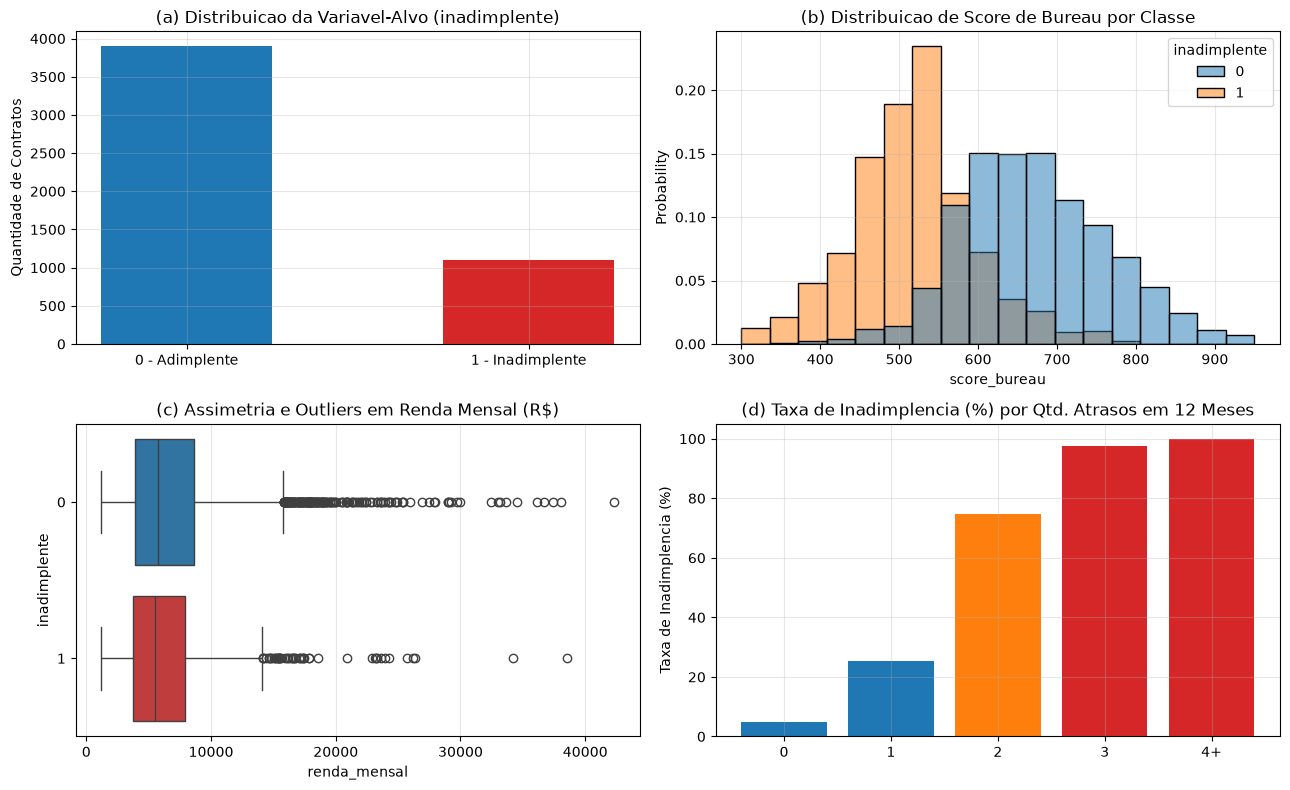

=== Taxa de Inadimplencia (%) por Qtd. de Atrasos em 12 Meses (Figura 1d) ===
                 count  taxa_pct
qtd_atrasos_12m                 
0                 2916      4.97
1                 1338     25.19
2                  488     74.59
3                  170     97.65
4+                  88    100.00

Outliers de renda_mensal pela regra do IQR (> R$ 15,394.97): 229 clientes (4.70%)


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# (a) Distribuicao da classe alvo
contagem = df_credito["inadimplente"].value_counts().sort_index()
axes[0, 0].bar(["0 - Adimplente", "1 - Inadimplente"], contagem.values, color=["#1f77b4", "#d62728"], width=0.5)
axes[0, 0].set_title("(a) Distribuicao da Variavel-Alvo (inadimplente)")
axes[0, 0].set_ylabel("Quantidade de Contratos")

# (b) Distribuicao do Score de Bureau por Classe
sns.histplot(data=df_credito, x="score_bureau", hue="inadimplente", stat="probability", common_norm=False, bins=18, ax=axes[0, 1])
axes[0, 1].set_title("(b) Distribuicao de Score de Bureau por Classe")

# (c) Boxplot de Renda Mensal (evidenciando assimetria e outliers)
sns.boxplot(data=df_credito, x="renda_mensal", y=df_credito["inadimplente"].astype(str), ax=axes[1, 0], palette=["#1f77b4", "#d62728"])
axes[1, 0].set_title("(c) Assimetria e Outliers em Renda Mensal (R$)")

# (d) Taxa de inadimplencia por faixa de atrasos em 12 meses
faixa_atrasos = df_credito["qtd_atrasos_12m"].clip(upper=4).map(lambda v: "4+" if v >= 4 else str(v))
taxa_atrasos = df_credito.groupby(faixa_atrasos)["inadimplente"].agg(["count", "mean"])
taxa_atrasos["taxa_pct"] = taxa_atrasos["mean"] * 100
axes[1, 1].bar(taxa_atrasos.index, taxa_atrasos["taxa_pct"].values, color=["#1f77b4", "#1f77b4", "#ff7f0e", "#d62728", "#d62728"])
axes[1, 1].set_title("(d) Taxa de Inadimplencia (%) por Qtd. Atrasos em 12 Meses")
axes[1, 1].set_ylabel("Taxa de Inadimplencia (%)")

plt.tight_layout()
plt.show()

print("=== Taxa de Inadimplencia (%) por Qtd. de Atrasos em 12 Meses (Figura 1d) ===")
print(taxa_atrasos[["count", "taxa_pct"]].round(2).to_string())
q1, q3 = df_credito["renda_mensal"].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
n_out = int((df_credito["renda_mensal"] > lim_sup).sum())
print(f"\nOutliers de renda_mensal pela regra do IQR (> R$ {lim_sup:,.2f}): {n_out} clientes ({n_out / df_credito['renda_mensal'].notna().sum() * 100:.2f}%)")


### Interpretação Técnica da Análise Exploratória (EDA)

A análise conjunta das estatísticas descritivas e da **Figura 1** evidencia quatro aspectos fundamentais para a modelagem:

1. **Desbalanceamento Moderado-Forte (`78,0%` vs. `22,0%`):** A classe minoritária (`inadimplente = 1`) representa pouco mais de 1 em cada 5 contratos. Conforme estudado na **Aula 02**, qualquer avaliação baseada isoladamente em *Accuracy* será distorcida pela classe majoritária (`Adimplente = 0`), tornando indispensável o uso de **F1-Score**, **Recall**, **Precision** e **ROC-AUC**.
2. **Assimetria Positiva e Presença de *Outliers* (`renda_mensal` e `valor_emprestimo`):** `renda_mensal` tem *skewness* de `2,10`, mediana de `R$ 5.683`, percentil 75% de `R$ 8.486` e máximo de `R$ 42.334`; pela regra do IQR, `229` clientes (`4,7%`) estão acima de `R$ 15.395`. `valor_emprestimo` tem *skewness* de `2,00` e chega a `R$ 145.000`. Conforme vimos na **Aula 04**:
   - Esses *outliers* esticam o intervalo $[\min, \max]$ do **`MinMaxScaler`**, comprimindo a maioria dos clientes numa faixa estreita — efeito que será medido no **Experimento 2**.
   - A imputação dos `125` valores ausentes de `renda_mensal` e `90` de `tempo_emprego_anos` deve ser feita pela **mediana** (robusta a *outliers*) e não pela média aritmética.
3. **Forte Sinal Preditivo Não Linear:** Clientes sem atrasos nos últimos 12 meses têm taxa de inadimplência de apenas **5,0%**; ela sobe para **25,2%** com 1 atraso, **74,6%** com 2 atrasos, **97,6%** com 3 atrasos e **100%** com 4 ou mais atrasos (Figura 1d). A mediana do `score_bureau` cai de `664` (adimplentes) para `519` (inadimplentes), e o `comprometimento_renda` mediano sobe de `36,0%` para `43,7%`.
4. **Renda isolada discrimina pouco:** a mediana de `renda_mensal` é parecida entre as classes (`R$ 5.760` vs. `R$ 5.488`). O risco está muito mais no comportamento (atrasos, score, uso do rotativo) do que no nível de renda.


### 4.3. Divisão Estratificada (Treino / Validação / Teste) e Prevenção de *Data Leakage* via `Pipeline`

Seguindo rigorosamente as diretrizes da **Aula 03 (Generalização e Validação)** e da **Aula 04 (Escala de Atributos)**:

1. **Divisão antes de qualquer transformação:** Separamos o dataset bruto em três partições mutuamente exclusivas mantendo a proporção exata de `22,00%` de inadimplentes (`stratify=y`):
   - **Conjunto de Treinamento (`70%` = `3.500` clientes):** Usado para ajustar os transformadores (`fit`) e realizar validação cruzada estratificada de 5 *folds* (`StratifiedKFold(n_splits=5)`).
   - **Conjunto de Validação (`15%` = `750` clientes):** Usado para calibrar o limiar de decisão $p^*$ orientado ao custo financeiro no Experimento 3, sem tocar no teste.
   - **Conjunto de Teste Oficial (`15%` = `750` clientes):** Cofre isolado (*held-out test set*), consultado exclusivamente na Seção 6 para a comparação final.
2. **Encapsulamento em `ColumnTransformer` + `Pipeline`:** Quando executamos `cross_validate`, cada *fold* de validação precisa que a mediana do `SimpleImputer`, a média/desvio-padrão do `StandardScaler` e as categorias do `OneHotEncoder` sejam calculados **exclusivamente nos 4 *folds* de treino daquela rodada**. O objeto `Pipeline` garante matematicamente **zero *Data Leakage***.

In [5]:
X = df_credito.drop(columns=["inadimplente"])
y = df_credito["inadimplente"]

# 1. Separar 15% para Teste Oficial (750 amostras)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED
)
# 2. Separar 15% do total (750 amostras = 17.647% dos 85% restantes) para Validacao
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=(750 / len(X_temp)), stratify=y_temp, random_state=SEED
)

print("=== Particionamento Estratificado (Antes de Qualquer Pre-processamento) ===")
for nome, part_x, part_y in [("Treino (70%)", X_train, y_train), ("Validacao (15%)", X_val, y_val), ("Teste Oficial (15%)", X_test, y_test)]:
    pos = int(part_y.sum())
    neg = len(part_y) - pos
    print(f"  {nome:20s}: Total = {len(part_x):4d} | Adimplentes (0) = {neg:4d} ({neg/len(part_y)*100:5.2f}%) | Inadimplentes (1) = {pos:3d} ({pos/len(part_y)*100:5.2f}%)")

def criar_preprocessador(scaler="standard"):
    """Cria ColumnTransformer livre de data leakage com escolha flexivel de escalonador."""
    if scaler == "standard":
        etapa_escala = ("scaler", StandardScaler())
    elif scaler == "minmax":
        etapa_escala = ("scaler", MinMaxScaler())
    else:
        etapa_escala = ("scaler", "passthrough")

    pipe_num = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        etapa_escala
    ])
    pipe_cat = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("num", pipe_num, num_cols),
        ("cat", pipe_cat, cat_cols)
    ])

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("\nPre-processador ColumnTransformer + Pipeline e StratifiedKFold(n_splits=5) prontos!")

=== Particionamento Estratificado (Antes de Qualquer Pre-processamento) ===
  Treino (70%)        : Total = 3500 | Adimplentes (0) = 2730 (78.00%) | Inadimplentes (1) = 770 (22.00%)
  Validacao (15%)     : Total =  750 | Adimplentes (0) =  585 (78.00%) | Inadimplentes (1) = 165 (22.00%)
  Teste Oficial (15%) : Total =  750 | Adimplentes (0) =  585 (78.00%) | Inadimplentes (1) = 165 (22.00%)

Pre-processador ColumnTransformer + Pipeline e StratifiedKFold(n_splits=5) prontos!


### 4.4. Implementação do Baseline (`DummyClassifier`) vs. `LightGBM` Inicial com Validação Cruzada

Conforme enfatizado na **Aula 02 (Métricas de Avaliação)** e no **Checklist de ML**, todo projeto deve partir de um **Baseline simples** para estabelecermos o piso de referência. Avaliamos no conjunto de treino via `5-Fold Stratified Cross-Validation` (`return_train_score=True`):
1. `DummyClassifier(strategy="most_frequent")`: aprova todos os clientes (prevê sempre classe `0`).
2. `DummyClassifier(strategy="stratified")`: sorteia previsões respeitando a proporção `78% / 22%`.
3. `LGBMClassifier(random_state=42)`: configuração padrão da biblioteca (`num_leaves=31`, `max_depth=-1`, `learning_rate=0.10`, `n_estimators=100`).

In [6]:
modelos_iniciais = {
    "Baseline (Dummy Most Frequent)": DummyClassifier(strategy="most_frequent", random_state=SEED),
    "Baseline (Dummy Stratified)"   : DummyClassifier(strategy="stratified", random_state=SEED),
    "LightGBM Padrao (Default L=31)": LGBMClassifier(
        n_estimators=100, learning_rate=0.10, num_leaves=31, max_depth=-1,
        random_state=SEED, verbose=-1, n_jobs=-1
    )
}

metricas_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]
linhas_baseline = []
for nome, estimador in modelos_iniciais.items():
    pipe = Pipeline([("prep", criar_preprocessador("standard")), ("clf", estimador)])
    res = cross_validate(pipe, X_train, y_train, cv=cv_5fold, scoring=metricas_cv, return_train_score=True)
    linhas_baseline.append({
        "Modelo": nome,
        "Acc Val": f"{res['test_accuracy'].mean():.4f} ± {res['test_accuracy'].std():.4f}",
        "Prec Val": f"{res['test_precision'].mean():.4f}",
        "Recall Val": f"{res['test_recall'].mean():.4f}",
        "F1 Treino": f"{res['train_f1'].mean():.4f}",
        "F1 Val": f"{res['test_f1'].mean():.4f} ± {res['test_f1'].std():.4f}",
        "Gap F1 (Tr-Val)": f"{res['train_f1'].mean() - res['test_f1'].mean():+.4f}",
        "ROC-AUC Val": f"{res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}"
    })

df_base_res = pd.DataFrame(linhas_baseline)
print("=== Comparacao Inicial (5-Fold Stratified Cross-Validation no Treino, N = 3.500) ===")
print(df_base_res.to_string(index=False))


=== Comparacao Inicial (5-Fold Stratified Cross-Validation no Treino, N = 3.500) ===
                        Modelo         Acc Val Prec Val Recall Val F1 Treino          F1 Val Gap F1 (Tr-Val)     ROC-AUC Val
Baseline (Dummy Most Frequent) 0.7800 ± 0.0000   0.0000     0.0000    0.0000 0.0000 ± 0.0000         +0.0000 0.5000 ± 0.0000
   Baseline (Dummy Stratified) 0.6589 ± 0.0084   0.2247     0.2247    0.2212 0.2247 ± 0.0191         -0.0035 0.5030 ± 0.0122
LightGBM Padrao (Default L=31) 0.9386 ± 0.0090   0.8809     0.8338    1.0000 0.8565 ± 0.0218         +0.1435 0.9800 ± 0.0051


### Diagnóstico Técnico da Implementação Inicial

Os resultados da validação cruzada de 5 *folds* confirmam dois pontos cruciais:

1. **A armadilha da Acurácia no Baseline:** O `DummyClassifier (Most Frequent)` atinge **78,00% de Acurácia**, mas obtém **`Recall = 0,0000`**, **`F1 = 0,0000`** e **`ROC-AUC = 0,5000`**. O `LightGBM Padrão` salta para **`Accuracy = 93,86%`**, **`F1 Val = 0,8565 ± 0,0218`** e **`ROC-AUC Val = 0,9800 ± 0,0051`**, comprovando que o modelo capturou os padrões não lineares da carteira.
2. **Memorização no LightGBM Padrão (`num_leaves=31, max_depth=-1`):** Observe a coluna **`Gap F1 (Tr-Val)`**: o `F1 Treino` atinge **`1,0000`** (o modelo acerta 100% do treino), enquanto o `F1 Val` fica em **`0,8565`**, um **gap de generalização de `+0,1435` (`14,35 p.p.`)**. Esse é o mecanismo teórico da Seção 2.3: sem restrição de profundidade e com `31` folhas por árvore em `100` iterações, o crescimento *leaf-wise* cria ramos específicos que memorizam o conjunto de treino. Esse diagnóstico motiva diretamente o **Experimento 1**.


## 5. Experimentação Controlada

Atendendo e ampliando o requisito do edital (que solicita pelo menos dois experimentos), conduzimos **três experimentos controlados** utilizando exclusivamente as partições de **Treino (`3.500`)** e **Validação (`750`)**, mantendo o **Teste Oficial (`750`)** intocado até a Seção 6.

---

### 5.1. Experimento 1 — Controle de Complexidade no Crescimento *Leaf-Wise* (`num_leaves`, `max_depth`, `min_child_samples` e `learning_rate`)

* **Hipótese Experimental (Conexão com a Aula 03 — Trade-off Viés × Variância):** No crescimento *leaf-wise*, aumentar indiscriminadamente `num_leaves` sem limitar `max_depth` nem `min_child_samples` reduz o erro de treino a quase zero, mas eleva drasticamente a variância (*overfitting*). Por outro lado, impor a restrição estrutural $\text{num\_leaves} < 2^{\text{max\_depth}}$ combinada com regularização $L_2$ (`reg_lambda`) e subamostragem (`subsample`, `colsample_bytree`) deve reduzir o *gap* treino-validação e maximizar o `F1-Score` e o `ROC-AUC` fora da amostra.
* **Desenho:** Avaliamos 6 configurações progressivas (`C1` a `C6`) via `5-Fold Stratified Cross-Validation` no treino (`N = 3.500`).

In [7]:
grade_exp1 = [
    ("C1 (L=3, d=2, lr=0.02) - Underfitting",
     dict(num_leaves=3, max_depth=2, learning_rate=0.02, n_estimators=80, min_child_samples=100, reg_lambda=5.0)),
    ("C2 (L=7, d=3, lr=0.05) - Conservador",
     dict(num_leaves=7, max_depth=3, learning_rate=0.05, n_estimators=120, min_child_samples=50, reg_lambda=2.0)),
    ("C3 (L=15, d=4, lr=0.05) - Regularizado",
     dict(num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0)),
    ("C4 (L=31, d=-1, lr=0.10) - Padrao LightGBM",
     dict(num_leaves=31, max_depth=-1, learning_rate=0.10, n_estimators=100, min_child_samples=20, reg_lambda=0.0)),
    ("C5 (L=63, d=-1, lr=0.15) - Alta Complexidade",
     dict(num_leaves=63, max_depth=-1, learning_rate=0.15, n_estimators=150, min_child_samples=10, reg_lambda=0.0)),
    ("C6 (L=127, d=-1, lr=0.25) - Complexidade Maxima",
     dict(num_leaves=127, max_depth=-1, learning_rate=0.25, n_estimators=200, min_child_samples=5, reg_lambda=0.0))
]

linhas_exp1 = []
for nome_cfg, params in grade_exp1:
    modelo = LGBMClassifier(**params, random_state=SEED, verbose=-1, n_jobs=-1)
    pipe = Pipeline([("prep", criar_preprocessador("standard")), ("clf", modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=cv_5fold, scoring=["f1", "roc_auc"], return_train_score=True)
    linhas_exp1.append({
        "Configuracao": nome_cfg,
        "F1 Treino": res["train_f1"].mean(),
        "F1 Val (5-Fold)": res["test_f1"].mean(),
        "F1 Val DP": res["test_f1"].std(),
        "Gap F1 (Tr-Val)": res["train_f1"].mean() - res["test_f1"].mean(),
        "AUC Treino": res["train_roc_auc"].mean(),
        "AUC Val (5-Fold)": res["test_roc_auc"].mean(),
    })

df_exp1 = pd.DataFrame(linhas_exp1)
idx_melhor_exp1 = int(df_exp1["F1 Val (5-Fold)"].idxmax())
print("=== Resultados do Experimento 1: Complexidade Leaf-Wise e Gap de Generalizacao ===")
print(df_exp1.round(4).to_string(index=False))
print(f"\nMaior F1 de validacao: {df_exp1.loc[idx_melhor_exp1, 'Configuracao']} "
      f"(F1 Val = {df_exp1.loc[idx_melhor_exp1, 'F1 Val (5-Fold)']:.4f} | AUC Val = {df_exp1.loc[idx_melhor_exp1, 'AUC Val (5-Fold)']:.4f} "
      f"| Gap = {df_exp1.loc[idx_melhor_exp1, 'Gap F1 (Tr-Val)'] * 100:.2f} p.p.)")


=== Resultados do Experimento 1: Complexidade Leaf-Wise e Gap de Generalizacao ===
                                   Configuracao  F1 Treino  F1 Val (5-Fold)  F1 Val DP  Gap F1 (Tr-Val)  AUC Treino  AUC Val (5-Fold)
          C1 (L=3, d=2, lr=0.02) - Underfitting     0.7814           0.7657     0.0252           0.0157      0.9594            0.9537
           C2 (L=7, d=3, lr=0.05) - Conservador     0.9031           0.8572     0.0186           0.0459      0.9911            0.9803
         C3 (L=15, d=4, lr=0.05) - Regularizado     0.9417           0.8589     0.0246           0.0828      0.9969            0.9825
     C4 (L=31, d=-1, lr=0.10) - Padrao LightGBM     1.0000           0.8565     0.0218           0.1435      1.0000            0.9800
   C5 (L=63, d=-1, lr=0.15) - Alta Complexidade     1.0000           0.8568     0.0225           0.1432      1.0000            0.9795
C6 (L=127, d=-1, lr=0.25) - Complexidade Maxima     1.0000           0.8569     0.0254           0.1431      1.00

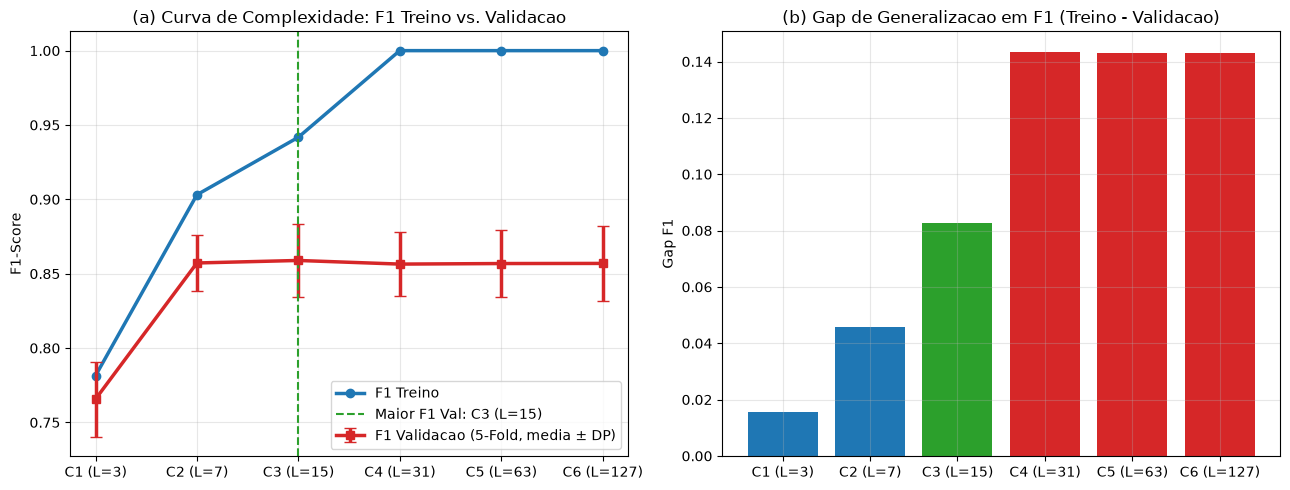

In [8]:
configs_curtas = ["C1 (L=3)", "C2 (L=7)", "C3 (L=15)", "C4 (L=31)", "C5 (L=63)", "C6 (L=127)"]
f1_tr_vals = df_exp1["F1 Treino"].values
f1_vl_vals = df_exp1["F1 Val (5-Fold)"].values
f1_vl_sd   = df_exp1["F1 Val DP"].values
gaps_vals  = df_exp1["Gap F1 (Tr-Val)"].values

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(configs_curtas, f1_tr_vals, marker="o", linewidth=2.5, label="F1 Treino", color="#1f77b4")
axes[0].errorbar(configs_curtas, f1_vl_vals, yerr=f1_vl_sd, marker="s", linewidth=2.5, capsize=4,
                 label="F1 Validacao (5-Fold, media ± DP)", color="#d62728")
axes[0].axvline(x=idx_melhor_exp1, color="#2ca02c", linestyle="--", label=f"Maior F1 Val: {configs_curtas[idx_melhor_exp1]}")
axes[0].set_title("(a) Curva de Complexidade: F1 Treino vs. Validacao")
axes[0].set_ylabel("F1-Score")
axes[0].legend()

cores_gap = ["#2ca02c" if i == idx_melhor_exp1 else ("#d62728" if g > 0.10 else "#1f77b4") for i, g in enumerate(gaps_vals)]
axes[1].bar(configs_curtas, gaps_vals, color=cores_gap)
axes[1].set_title("(b) Gap de Generalizacao em F1 (Treino - Validacao)")
axes[1].set_ylabel("Gap F1")
plt.tight_layout()
plt.show()


### Análise Técnica do Experimento 1

A **Figura 2** ilustra o **Trade-off Viés × Variância** discutido na **Aula 03**:

1. **Região de *Underfitting* (`C1: num_leaves=3, max_depth=2`):** Árvores excessivamente rasas, com poucas iterações (`80`) e `lr=0.02`, têm alto viés: treino (`0,7814`) e validação (`0,7657`) ficam baixos, embora o *gap* seja mínimo (`+0,0157`).
2. **Melhor Generalização (`C3: num_leaves=15, max_depth=4, min_child_samples=30, lr=0.05`):** Respeitando $\text{num\_leaves} = 15 < 2^4 = 16$, com pelo menos `30` contratos por folha, regularização $L_2$ (`reg_lambda=1.0`) e amostragem de linhas/colunas (`0,8`), o `C3` obteve o **maior F1 de validação (`0,8589 ± 0,0246`)** e o **maior ROC-AUC de validação (`0,9825`)**, com *gap* de **`+0,0828` (`8,28 p.p.`)**.
3. **Região de Memorização (`C4`, `C5` e `C6`):** Com `max_depth=-1` e `num_leaves` de `31` a `127`, o modelo atinge **`F1 Treino = 1,0000`** e **`AUC Treino = 1,0000`** — decora o treino — e o *gap* sobe para **`+0,14`**.

**Leitura honesta dos resultados:** nesta base, o excesso de complexidade **não derrubou fortemente** a validação — o F1 de `C4` a `C6` (`≈ 0,857`) fica apenas `0,2 p.p.` abaixo do `C3`, diferença menor que o desvio-padrão entre *folds* (`≈ 0,025`). Ou seja, **`C2` a `C6` empatam estatisticamente em F1 de validação**; o que os diferencia é o *gap*. Escolhemos o `C3` porque ele entrega o mesmo desempenho fora da amostra **sem memorizar o treino** (gap `8,3 p.p.` contra `14,3 p.p.`), o que o torna mais confiável quando os dados de produção mudarem. A lição é que, no LightGBM, **o desempenho de treino não serve como indicador de qualidade** — `num_leaves` e `max_depth` precisam ser controlados e avaliados por validação cruzada.


---

### 5.2. Experimento 2 — Sensibilidade à Escala de Atributos e *Outliers* (`Sem Escala` vs. `MinMaxScaler` vs. `StandardScaler`)

* **Hipótese Experimental (Conexão direta com a Aula 04 — Escala de Atributos, Normalização e Padronização):**
  - Algoritmos baseados em distância euclidiana (**K-NN**) e em produtos internos/margens geométricas no espaço de atributos (**SVM com Kernel RBF**, $K(\mathbf{x}_i, \mathbf{x}_j) = \exp(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2)$) são altamente sensíveis à escala das variáveis: sem escalonamento, atributos em dezenas de milhares de reais (`valor_emprestimo` e `renda_mensal`) dominam completamente o cálculo de distância, anulando atributos em $[0, 1]$ (`comprometimento_renda`). Além disso, como vimos na EDA que `renda_mensal` possui *outliers* severos, o `MinMaxScaler` sofrerá compressão de faixa em comparação ao `StandardScaler`.
  - Por outro lado, tanto a **Random Forest** quanto o **LightGBM** constroem partições ortogonais baseadas em **ordenação / quantis de histogramas** ($x_{ij} \le \tau$). Como qualquer transformação monotônica estritamente crescente $g(x) = a x + b$ ($a > 0$) preserva a ordem relativa de todas as amostras ($x_1 < x_2 \iff a x_1 + b < a x_2 + b$), ambos os algoritmos baseados em árvores devem exibir **invariância exata à escala**.

In [9]:
modelos_exp2 = {
    "K-NN (n_neighbors=7)" : KNeighborsClassifier(n_neighbors=7),
    "SVM (Kernel RBF, C=1)": SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED),
    "Random Forest (d=8)"  : RandomForestClassifier(n_estimators=160, max_depth=8, min_samples_leaf=15, random_state=SEED, n_jobs=-1),
    "LightGBM (C3)"        : LGBMClassifier(
        num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160,
        min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=SEED, verbose=-1, n_jobs=-1
    )
}

regimes_escala = [
    ("none", "1. Sem Escalonamento (Bruto)"),
    ("minmax", "2. MinMaxScaler [0,1]"),
    ("standard", "3. StandardScaler (Z-Score)")
]

resultados_exp2 = {}
linhas_exp2 = []
for nome_mod, mod in modelos_exp2.items():
    scores_regime = {}
    for cod_esc, rot_esc in regimes_escala:
        pipe = Pipeline([("prep", criar_preprocessador(cod_esc)), ("clf", mod)])
        res = cross_validate(pipe, X_train, y_train, cv=cv_5fold, scoring=["f1", "roc_auc"])
        scores_regime[cod_esc] = (res["test_f1"].mean(), res["test_roc_auc"].mean())
    resultados_exp2[nome_mod] = scores_regime
    f1_bruto, f1_std = scores_regime["none"][0], scores_regime["standard"][0]
    linhas_exp2.append({
        "Algoritmo": nome_mod,
        "F1 Sem Escala": f"{f1_bruto:.4f}",
        "F1 MinMaxScaler": f"{scores_regime['minmax'][0]:.4f}",
        "F1 StandardScaler": f"{f1_std:.4f}",
        "Variacao F1 (Std - Bruto)": f"{(f1_std - f1_bruto) * 100:+.2f} p.p.",
        "AUC Sem Escala": f"{scores_regime['none'][1]:.4f}",
        "AUC MinMaxScaler": f"{scores_regime['minmax'][1]:.4f}",
        "AUC StandardScaler": f"{scores_regime['standard'][1]:.4f}"
    })

df_exp2 = pd.DataFrame(linhas_exp2)
print("=== Resultados do Experimento 2: Impacto da Escala e Outliers (5-Fold CV no Treino) ===")
print(df_exp2.to_string(index=False))


=== Resultados do Experimento 2: Impacto da Escala e Outliers (5-Fold CV no Treino) ===
            Algoritmo F1 Sem Escala F1 MinMaxScaler F1 StandardScaler Variacao F1 (Std - Bruto) AUC Sem Escala AUC MinMaxScaler AUC StandardScaler
 K-NN (n_neighbors=7)        0.1195          0.6560            0.8079               +68.84 p.p.         0.5824           0.9206             0.9576
SVM (Kernel RBF, C=1)        0.0000          0.8445            0.8605               +86.05 p.p.         0.8938           0.9801             0.9810
  Random Forest (d=8)        0.8056          0.8056            0.8050                -0.06 p.p.         0.9714           0.9714             0.9714
        LightGBM (C3)        0.8589          0.8604            0.8589                +0.00 p.p.         0.9823           0.9824             0.9825


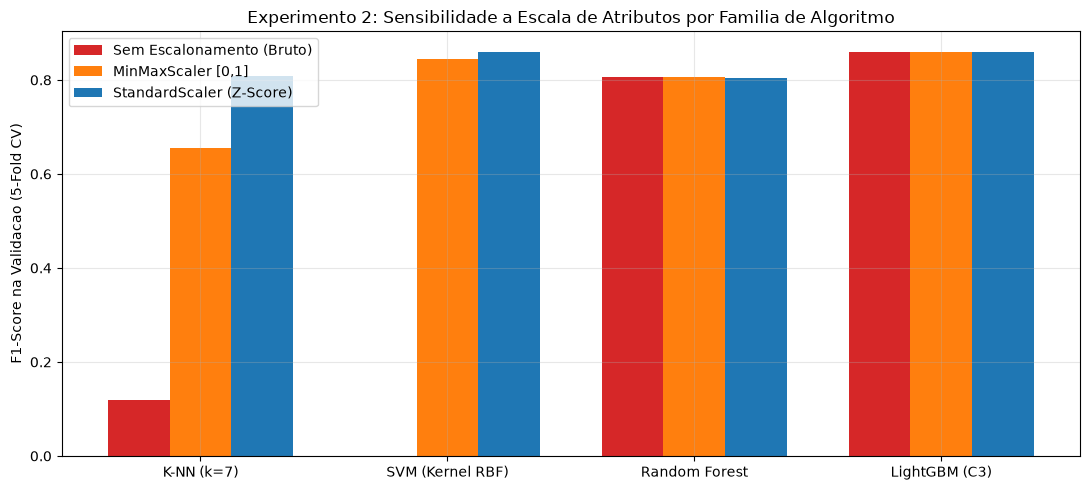

In [10]:
algos_nomes = ["K-NN (k=7)", "SVM (Kernel RBF)", "Random Forest", "LightGBM (C3)"]
f1_bruto  = [resultados_exp2[m]["none"][0] for m in modelos_exp2]
f1_minmax = [resultados_exp2[m]["minmax"][0] for m in modelos_exp2]
f1_std    = [resultados_exp2[m]["standard"][0] for m in modelos_exp2]

x = np.arange(len(algos_nomes))
largura = 0.25

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - largura, f1_bruto, largura, label="Sem Escalonamento (Bruto)", color="#d62728")
ax.bar(x, f1_minmax, largura, label="MinMaxScaler [0,1]", color="#ff7f0e")
ax.bar(x + largura, f1_std, largura, label="StandardScaler (Z-Score)", color="#1f77b4")
ax.set_xticks(x)
ax.set_xticklabels(algos_nomes)
ax.set_ylabel("F1-Score na Validacao (5-Fold CV)")
ax.set_title("Experimento 2: Sensibilidade a Escala de Atributos por Familia de Algoritmo")
ax.legend()
plt.tight_layout()
plt.show()


### Análise Técnica do Experimento 2

Os resultados da tabela e da **Figura 3** comprovam na prática os conceitos da **Aula 04**:

1. **Colapso do K-NN e do SVM sem escalonamento:** Sem padronização, o `K-NN` obtém apenas `F1 = 0,1195` e o `SVM (RBF)` obtém **`F1 = 0,0000`** — com `gamma="scale"` e atributos em dezenas de milhares de reais, o *kernel* RBF fica dominado por `valor_emprestimo` e `renda_mensal`, e o SVM passa a prever praticamente só a classe majoritária. Como `valor_emprestimo` vai até `R$ 145.000` e `comprometimento_renda` fica entre `0,05` e `0,88`, a distância euclidiana $\|\mathbf{x}_i - \mathbf{x}_j\|^2$ é quase totalmente determinada pelos atributos monetários, ignorando atrasos, score e uso do rotativo.
2. **Superioridade do `StandardScaler` sobre o `MinMaxScaler` na presença de *Outliers*:** Com `MinMaxScaler`, o `K-NN` sobe para `0,6560` e o `SVM` para `0,8445`; com `StandardScaler`, chegam a `0,8079` (**+68,8 p.p.** sobre o bruto) e `0,8605` (**+86,1 p.p.**). A diferença é maior no K-NN: os *outliers* de renda e empréstimo comprimem a maioria dos clientes numa faixa estreita do `MinMaxScaler`.
3. **Invariância prática da Random Forest e do LightGBM:** O `F1` da Random Forest varia no máximo `0,06 p.p.` (`0,8050`–`0,8056`) e o do LightGBM `0,15 p.p.` (`0,8589`–`0,8604`), com ROC-AUC praticamente idêntico nos três regimes. Árvores particionam por limiares ($x_{ij} \le \tau$) e transformações monotônicas preservam a ordem dos exemplos, então as divisões são equivalentes; as diferenças residuais vêm de arredondamento numérico na posição dos limiares e na construção dos *bins* do histograma, não de perda de informação. Essa propriedade é uma **vantagem operacional do LightGBM** em pipelines com variáveis de escalas heterogêneas.


---

### 5.3. Experimento 3 — Desbalanceamento de Classes (`scale_pos_weight`) e Calibração do Limiar de Decisão ($p^*$) pelo Custo Financeiro

* **Hipótese Experimental (Conexão direta com a Aula 02 — Métricas de Avaliação, ROC e Limiar de Decisão):**
  - Por padrão, qualquer classificador probabilístico utiliza o limiar simétrico $p = 0,50$ ($\hat{y} = 1 \iff \hat{P}(y=1|\mathbf{x}) \ge 0,50$). Porém, quando a classe positiva representa apenas `22,0%` da carteira e o custo de um **Falso Negativo ($\text{R\$ } 8.500,00$)** é **18,9 vezes maior** que o custo de um **Falso Positivo ($\text{R\$ } 450,00$)**, o limiar `0,50` deixa escapar muitos inadimplentes. Pela teoria de decisão de Bayes, com probabilidades bem calibradas o limiar que minimiza o custo esperado é $p_{\text{Bayes}} = \frac{\text{Custo}_{\text{FP}}}{\text{Custo}_{\text{FN}} + \text{Custo}_{\text{FP}}} = \frac{450}{8.950} \approx 0,05$.
  - Testamos duas abordagens no **conjunto de validação (`N = 750`, sendo `585` adimplentes e `165` inadimplentes)**:
    1. Ponderar a função de perda do LightGBM com `scale_pos_weight = 2730 / 770 = 3.55` mantendo $p = 0,50$.
    2. Manter as probabilidades bem calibradas do `LightGBM C3` e encontrar na validação, por **varredura fina de limiares (passo `0,01`)**, o **limiar ótimo de decisão $p^*$** que minimiza o **Custo Financeiro Total** ($\text{Custo} = 8.500 \times \text{FN} + 450 \times \text{FP}$).

In [11]:
CUSTO_FN = 8500.0  # Prejuizo medio por inadimplente aprovado (R$)
CUSTO_FP = 450.0   # Custo comercial/mesa de credito por bom pagador revisado (R$)

PARAMS_C3 = dict(
    num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160,
    min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=SEED, verbose=-1, n_jobs=-1
)

def avaliar_limiar(y_true, probs, p_cut):
    pred = (probs >= p_cut).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_true, pred).ravel()
    return {
        "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1-Score": f1_score(y_true, pred),
        "Custo (R$)": fn * CUSTO_FN + fp * CUSTO_FP,
    }

# (1) LightGBM C3 treinado somente no Treino; probabilidades na Validacao
pipe_lgbm_c3 = Pipeline([("prep", criar_preprocessador("standard")), ("clf", LGBMClassifier(**PARAMS_C3))])
pipe_lgbm_c3.fit(X_train, y_train)
prob_val = pipe_lgbm_c3.predict_proba(X_val)[:, 1]

# (2) LightGBM C3 com scale_pos_weight = N_neg / N_pos do treino (limiar 0,50)
spw = (y_train == 0).sum() / (y_train == 1).sum()
pipe_lgbm_spw = Pipeline([("prep", criar_preprocessador("standard")), ("clf", LGBMClassifier(**PARAMS_C3, scale_pos_weight=spw))])
pipe_lgbm_spw.fit(X_train, y_train)
prob_val_spw = pipe_lgbm_spw.predict_proba(X_val)[:, 1]

# (3) Varredura fina de limiares (passo 0,01) na Validacao para minimizar o custo financeiro
grade_fina = np.round(np.arange(0.01, 0.991, 0.01), 2)
df_varredura = pd.DataFrame([{"Limiar": p, **avaliar_limiar(y_val, prob_val, p)} for p in grade_fina])
# Em caso de empate de custo, escolhe o maior limiar (menos revisoes manuais)
custo_min = df_varredura["Custo (R$)"].min()
P_STAR = float(df_varredura.loc[df_varredura["Custo (R$)"] == custo_min, "Limiar"].max())
p_teorico = CUSTO_FP / (CUSTO_FN + CUSTO_FP)

limiares_exibir = sorted(set([0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, P_STAR]))
df_exp3 = df_varredura[df_varredura["Limiar"].isin(limiares_exibir)].copy()
df_exp3["Limiar"] = df_exp3["Limiar"].map(lambda p: f"{p:.2f}" + (" *" if p == P_STAR else ""))
print("=== Experimento 3: Varredura de Limiares de Decisao na Validacao (N = 750) ===")
print(df_exp3.round(4).to_string(index=False))

res_050 = avaliar_limiar(y_val, prob_val, 0.50)
res_spw = avaliar_limiar(y_val, prob_val_spw, 0.50)
res_pst = avaliar_limiar(y_val, prob_val, P_STAR)
df_cmp3 = pd.DataFrame([
    {"Abordagem": "1. LightGBM C3 (p = 0,50)", **res_050},
    {"Abordagem": f"2. LightGBM C3 + scale_pos_weight = {spw:.2f} (p = 0,50)", **res_spw},
    {"Abordagem": f"3. LightGBM C3 + limiar calibrado (p* = {P_STAR:.2f})", **res_pst},
])
print("\n=== Comparacao Direta na Validacao ===")
print(df_cmp3.round(4).to_string(index=False))
economia = res_050["Custo (R$)"] - res_pst["Custo (R$)"]
print(f"\nLimiar teorico de Bayes (Custo_FP / (Custo_FN + Custo_FP)) = {p_teorico:.4f} | Limiar empirico p* = {P_STAR:.2f}")
print(f"Economia na Validacao (p* vs p = 0,50): R$ {economia:,.2f} ({-economia / res_050['Custo (R$)'] * 100:.2f}% de custo)")


=== Experimento 3: Varredura de Limiares de Decisao na Validacao (N = 750) ===
Limiar  VP  FP  FN  VN  Precision  Recall  F1-Score  Custo (R$)
  0.05 164 113   1 472     0.5921  0.9939    0.7421     59350.0
0.06 * 164 106   1 479     0.6074  0.9939    0.7540     56200.0
  0.10 161  74   4 511     0.6851  0.9758    0.8050     67300.0
  0.15 159  55   6 530     0.7430  0.9636    0.8391     75750.0
  0.20 156  48   9 537     0.7647  0.9455    0.8455     98100.0
  0.30 152  33  13 552     0.8216  0.9212    0.8686    125350.0
  0.40 143  29  22 556     0.8314  0.8667    0.8487    200050.0
  0.50 133  22  32 563     0.8581  0.8061    0.8312    281900.0
  0.60 123  15  42 570     0.8913  0.7455    0.8119    363750.0
  0.70 113   7  52 578     0.9417  0.6848    0.7930    445150.0
  0.80 107   4  58 581     0.9640  0.6485    0.7754    494800.0

=== Comparacao Direta na Validacao ===
                                          Abordagem  VP  FP  FN  VN  Precision  Recall  F1-Score  Custo (R$)
    

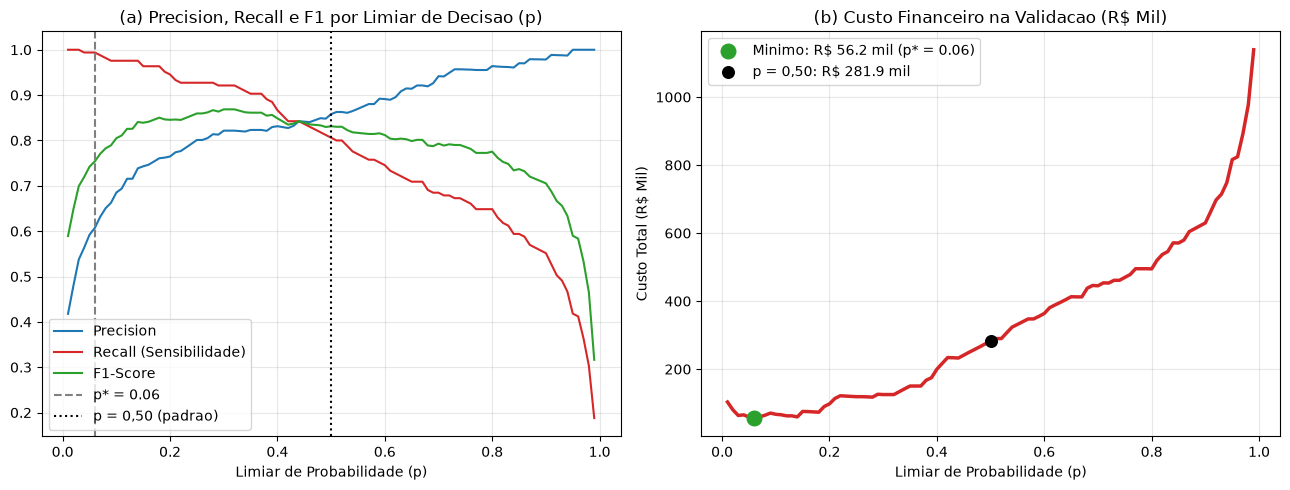

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
p_grid = df_varredura["Limiar"].values

axes[0].plot(p_grid, df_varredura["Precision"], label="Precision", color="#1f77b4")
axes[0].plot(p_grid, df_varredura["Recall"], label="Recall (Sensibilidade)", color="#d62728")
axes[0].plot(p_grid, df_varredura["F1-Score"], label="F1-Score", color="#2ca02c")
axes[0].axvline(P_STAR, color="gray", linestyle="--", label=f"p* = {P_STAR:.2f}")
axes[0].axvline(0.50, color="black", linestyle=":", label="p = 0,50 (padrao)")
axes[0].set_title("(a) Precision, Recall e F1 por Limiar de Decisao (p)")
axes[0].set_xlabel("Limiar de Probabilidade (p)")
axes[0].legend()

axes[1].plot(p_grid, df_varredura["Custo (R$)"] / 1000, color="#d62728", linewidth=2.5)
axes[1].scatter([P_STAR], [res_pst["Custo (R$)"] / 1000], color="#2ca02c", s=110, zorder=5,
                label=f"Minimo: R$ {res_pst['Custo (R$)'] / 1000:,.1f} mil (p* = {P_STAR:.2f})")
axes[1].scatter([0.50], [res_050["Custo (R$)"] / 1000], color="black", s=70, zorder=5,
                label=f"p = 0,50: R$ {res_050['Custo (R$)'] / 1000:,.1f} mil")
axes[1].set_title("(b) Custo Financeiro na Validacao (R$ Mil)")
axes[1].set_xlabel("Limiar de Probabilidade (p)")
axes[1].set_ylabel("Custo Total (R$ Mil)")
axes[1].legend()
plt.tight_layout()
plt.show()


### Análise Técnica do Experimento 3

O **Experimento 3** e a **Figura 4** mostram por que não se deve parar no `.predict()` padrão (`p = 0,50`), aplicando diretamente a teoria da **Aula 02**:

1. **No limiar padrão (`p = 0,50`):** O modelo tem boa precisão (`85,81%`, `22` Falsos Positivos), mas deixa passar **32 inadimplentes (`FN = 32`, `Recall = 80,61%`)**, gerando um custo de **R\$ 281.900,00** na validação.
2. **Com `scale_pos_weight = 3,55` (`p = 0,50`):** Aumentar o peso dos exemplos positivos reduz os Falsos Negativos para `11` (`Recall = 93,33%`) e o custo para **R\$ 110.150,00**, com o **maior F1 entre as três abordagens (`0,8652`)**. O preço é distorcer as probabilidades estimadas, que deixam de representar a taxa real de inadimplência.
3. **Com calibração direta do limiar (`p* = 0,06`):** A varredura fina encontrou o custo mínimo em **`p* = 0,06`**, praticamente igual ao **limiar teórico de Bayes ($450 / 8.950 \approx 0,05$)** — evidência de que as probabilidades do LightGBM estão razoavelmente calibradas. Nesse limiar, o **Recall sobe para `99,39%`** (`164` dos `165` inadimplentes; apenas `1` Falso Negativo) e o custo cai para **R\$ 56.200,00** — **redução de 80,06% (economia de R\$ 225.700,00 a cada 750 contratos)** em relação a `p = 0,50`.

**Trade-off importante:** o limiar ótimo para o **custo** não é o ótimo para o **F1**. Em `p* = 0,06`, o F1 cai para `0,7540` (contra `0,8312` em `0,50`), porque o modelo envia `106` bons pagadores para revisão manual (`Precision = 60,74%`). Como cada FN custa `18,9` vezes mais que um FP, aceitar mais revisões manuais é a decisão de negócio correta — e é exatamente isso que uma métrica puramente estatística como o F1 não captura.


## 6. Avaliação Comparativa Final no Conjunto de Teste Oficial (`N = 750`)

Com todas as decisões de arquitetura (`Configuração C3: num_leaves=15, max_depth=4, min_child_samples=30, learning_rate=0.05, n_estimators=160`) e o limiar de decisão (`p* = 0,06`) travados utilizando apenas o Treino e a Validação, abrimos agora pela primeira e única vez o **Conjunto de Teste Oficial (`750` contratos: `585` adimplentes e `165` inadimplentes)**.

Comparamos o **LightGBM** contra **todas as técnicas supervisionadas estudadas na disciplina de Aprendizado de Máquina I**:
1. **Baseline (`DummyClassifier - Most Frequent`)**
2. **Naive Bayes Gaussiano (`GaussianNB`)**
3. **K-Vizinhos Mais Próximos (`KNeighborsClassifier`, $k=7$ com `StandardScaler`)**
4. **Árvore de Decisão Podada (`DecisionTreeClassifier`, `max_depth=5, min_samples_leaf=25`)**
5. **Random Forest (`RandomForestClassifier`, `160` árvores, `max_depth=8, min_samples_leaf=15`)**
6. **Support Vector Machine (`SVC`, Kernel RBF, $C=1,0$, $\gamma=\text{'scale'}$ com `StandardScaler`)**
7. **LightGBM Regularizado (`LGBMClassifier C3` em `p = 0,50` e no limiar calibrado `p* = 0,06`)**

In [13]:
# Treinamento final em Treino (N=3.500) e avaliacao unica no Teste Oficial (N=750)
# O limiar P_STAR foi escolhido no Experimento 3 usando apenas a Validacao.
modelos_finais = [
    ("1. Baseline (Dummy Most Freq)", DummyClassifier(strategy="most_frequent", random_state=SEED), 0.50),
    ("2. Naive Bayes (GaussianNB)", GaussianNB(), 0.50),
    ("3. K-NN (k=7 + StandardScaler)", KNeighborsClassifier(n_neighbors=7), 0.50),
    ("4. Decision Tree Podada (d=5)", DecisionTreeClassifier(max_depth=5, min_samples_leaf=25, random_state=SEED), 0.50),
    ("5. SVM (Kernel RBF, C=1.0)", SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED), 0.50),
    ("6. Random Forest (Bagging 160 arv)", RandomForestClassifier(n_estimators=160, max_depth=8, min_samples_leaf=15, random_state=SEED, n_jobs=-1), 0.50),
    ("7. LightGBM C3 (p = 0.50 Padrao)", LGBMClassifier(**PARAMS_C3), 0.50),
]

N_REPETICOES_TEMPO = 5  # mediana de 5 treinos para reduzir ruido na medicao de tempo
linhas_teste = []
probs_teste = {}
pipes_finais = {}
for nome_m, clf_m, limiar_m in modelos_finais:
    tempos = []
    for _ in range(N_REPETICOES_TEMPO):
        pipe_m = Pipeline([("prep", criar_preprocessador("standard")), ("clf", clf_m)])
        t0 = time.perf_counter()
        pipe_m.fit(X_train, y_train)
        tempos.append(time.perf_counter() - t0)
    t_treino = float(np.median(tempos))
    probs_test = pipe_m.predict_proba(X_test)[:, 1]
    probs_teste[nome_m] = probs_test
    pipes_finais[nome_m] = pipe_m
    linhas_teste.append({"Modelo": nome_m, "Limiar": limiar_m, "Treino (s)": t_treino,
                         "Accuracy": accuracy_score(y_test, (probs_test >= limiar_m).astype(int)),
                         "ROC-AUC": roc_auc_score(y_test, probs_test),
                         **avaliar_limiar(y_test, probs_test, limiar_m)})

# Mesmo modelo LightGBM C3, agora com o limiar calibrado na Validacao
nome_lgbm = "7. LightGBM C3 (p = 0.50 Padrao)"
linha_lgbm = next(l for l in linhas_teste if l["Modelo"] == nome_lgbm)
probs_lgbm = probs_teste[nome_lgbm]
linhas_teste.append({"Modelo": f"8. LightGBM C3 (p* = {P_STAR:.2f} Custo)", "Limiar": P_STAR, "Treino (s)": linha_lgbm["Treino (s)"],
                     "Accuracy": accuracy_score(y_test, (probs_lgbm >= P_STAR).astype(int)),
                     "ROC-AUC": roc_auc_score(y_test, probs_lgbm),
                     **avaliar_limiar(y_test, probs_lgbm, P_STAR)})

df_teste_final = pd.DataFrame(linhas_teste)[["Modelo", "Limiar", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC",
                                             "VP", "FP", "FN", "VN", "Treino (s)", "Custo (R$)"]]
print("=== AVALIACAO COMPARATIVA FINAL NO CONJUNTO DE TESTE OFICIAL (N = 750: 585 Adimplentes | 165 Inadimplentes) ===")
print(df_teste_final.round(4).to_string(index=False))


=== AVALIACAO COMPARATIVA FINAL NO CONJUNTO DE TESTE OFICIAL (N = 750: 585 Adimplentes | 165 Inadimplentes) ===
                            Modelo  Limiar  Accuracy  Precision  Recall  F1-Score  ROC-AUC  VP  FP  FN  VN  Treino (s)  Custo (R$)
     1. Baseline (Dummy Most Freq)    0.50    0.7800     0.0000  0.0000    0.0000   0.5000   0   0 165 585      0.0126   1402500.0
       2. Naive Bayes (GaussianNB)    0.50    0.9040     0.7541  0.8364    0.7931   0.9650 138  45  27 540      0.0141    249750.0
    3. K-NN (k=7 + StandardScaler)    0.50    0.9160     0.8542  0.7455    0.7961   0.9598 123  21  42 564      0.0130    366450.0
     4. Decision Tree Podada (d=5)    0.50    0.9080     0.8117  0.7576    0.7837   0.9495 125  29  40 556      0.0235    353050.0
        5. SVM (Kernel RBF, C=1.0)    0.50    0.9400     0.8896  0.8303    0.8589   0.9814 137  17  28 568      0.6069    245650.0
6. Random Forest (Bagging 160 arv)    0.50    0.9160     0.8400  0.7636    0.8000   0.9695 126  24  39

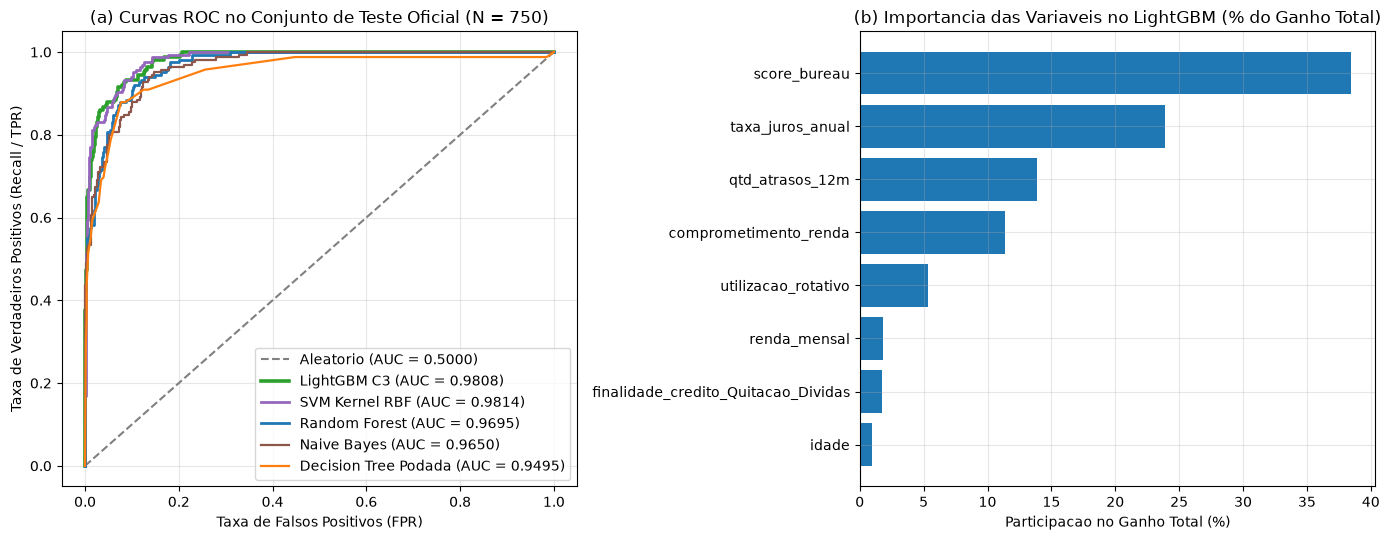

=== Importancia por Ganho (% do total) ===
score_bureau                           38.44
taxa_juros_anual                       23.92
qtd_atrasos_12m                        13.90
comprometimento_renda                  11.33
utilizacao_rotativo                     5.35
renda_mensal                            1.83
finalidade_credito_Quitacao_Dividas     1.71
idade                                   0.98
tipo_moradia_Alugada                    0.66
tempo_emprego_anos                      0.63

Top 3 somadas: 76.3% | Top 4 somadas: 87.6%


In [14]:
# Visualizacao Final no Conjunto de Teste Oficial: Curvas ROC reais e Importancia de Variaveis do LightGBM
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Curvas ROC calculadas com roc_curve sobre as probabilidades do Teste Oficial
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio (AUC = 0.5000)")
cores_roc = {
    "7. LightGBM C3 (p = 0.50 Padrao)": ("LightGBM C3", "#2ca02c", 2.6),
    "5. SVM (Kernel RBF, C=1.0)": ("SVM Kernel RBF", "#9467bd", 2.0),
    "6. Random Forest (Bagging 160 arv)": ("Random Forest", "#1f77b4", 2.0),
    "2. Naive Bayes (GaussianNB)": ("Naive Bayes", "#8c564b", 1.6),
    "4. Decision Tree Podada (d=5)": ("Decision Tree Podada", "#ff7f0e", 1.6),
}
for nome_m, (rotulo, cor, lw) in cores_roc.items():
    fpr, tpr, _ = roc_curve(y_test, probs_teste[nome_m])
    axes[0].plot(fpr, tpr, color=cor, linewidth=lw, label=f"{rotulo} (AUC = {roc_auc_score(y_test, probs_teste[nome_m]):.4f})")
axes[0].set_title("(a) Curvas ROC no Conjunto de Teste Oficial (N = 750)")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall / TPR)")
axes[0].legend(loc="lower right")

# (b) Importancia por ganho (gain) extraida do booster do LightGBM final
pipe_lgbm_final = pipes_finais[nome_lgbm]
nomes_feat = [n.split("__", 1)[1] for n in pipe_lgbm_final.named_steps["prep"].get_feature_names_out()]
ganho = pipe_lgbm_final.named_steps["clf"].booster_.feature_importance(importance_type="gain")
imp_gain = (pd.Series(ganho, index=nomes_feat) / ganho.sum() * 100).sort_values(ascending=False)
top8 = imp_gain.head(8)[::-1]
axes[1].barh(top8.index, top8.values, color="#1f77b4")
axes[1].set_title("(b) Importancia das Variaveis no LightGBM (% do Ganho Total)")
axes[1].set_xlabel("Participacao no Ganho Total (%)")
plt.tight_layout()
plt.show()

print("=== Importancia por Ganho (% do total) ===")
print(imp_gain.round(2).head(10).to_string())
print(f"\nTop 3 somadas: {imp_gain.head(3).sum():.1f}% | Top 4 somadas: {imp_gain.head(4).sum():.1f}%")


## 7. Análise Crítica: Vantagens, Limitações e Diferenças em Relação às Técnicas Estudadas na Disciplina

### 7.1. Interpretação Técnica dos Resultados no Conjunto de Teste Oficial

A avaliação final na partição de teste (`N = 750`, isolada durante todo o desenvolvimento) mostra:

1. **No mesmo limiar padrão (`p = 0,50`):**
   - O **LightGBM (`C3`)** obteve a maior **Accuracy (`94,13%`)**, a maior **Precision (`90,07%`)** e o maior **F1-Score (`0,8608`)**, com ROC-AUC de **`0,9808`**.
   - O **SVM com Kernel RBF** ficou **praticamente empatado**: `F1 = 0,8589` e o maior ROC-AUC do teste (`0,9814`). A diferença entre os dois (`0,2 p.p.` em F1 e `0,06 p.p.` em AUC) equivale a um ou dois clientes e não é significativa num teste de 750 contratos. A vantagem concreta do LightGBM sobre o SVM está no **tempo de treino: `≈ 0,09 s` contra `≈ 0,61 s` (≈ 7 vezes mais rápido)** — diferença que cresce rapidamente com o tamanho da base, pois o SVM escala de forma superlinear ($O(N^2)$ a $O(N^3)$) e o LightGBM de forma aproximadamente linear.
   - Contra a **Random Forest (`F1 = 0,8000`, `ROC-AUC = 0,9695`)**, o LightGBM ganhou **+6,1 p.p. em F1** e **+1,1 p.p. em ROC-AUC**, treinando **≈ 3 vezes mais rápido** (`≈ 0,09 s` contra `≈ 0,28 s`).
   - O **Naive Bayes** obteve o maior **Recall** no limiar `0,50` (`83,64%`), mas com precisão bem menor (`75,41%`).
2. **Com o limiar calibrado para o negócio (`p* = 0,06`):**
   - O **LightGBM (`C3, p* = 0,06`)** detectou **163 dos 165 inadimplentes (`Recall = 98,79%`, apenas `2` Falsos Negativos)** e reduziu o custo no teste para **R\$ 70.100,00** — **95,0% menor que o Baseline** (`R$ 1.402.500,00`), **72,3% menor que o próprio LightGBM em `p = 0,50`** (`R$ 253.250,00`) e **71,5% menor que o melhor modelo em `p = 0,50` (SVM, `R$ 245.650,00`)**.
   - Em contrapartida, `118` bons pagadores vão para revisão manual (`Precision = 58,01%`, `F1 = 0,7309`). O resultado no teste confirma o que foi observado na validação — o limiar escolhido sem olhar o teste generalizou bem.
3. **Interpretabilidade Global via Ganho (*Feature Importance*):**
   - Conforme a **Figura 5(b)**, `score_bureau` (**38,4%**), `taxa_juros_anual` (**23,9%**) e `qtd_atrasos_12m` (**13,9%**) somam **76,3% do ganho total**; com `comprometimento_renda` (**11,3%**), as quatro chegam a **87,6%**.
   - **Cuidado na leitura:** `taxa_juros_anual` aparece em 2º lugar porque é precificada a partir do score e dos atrasos — ela funciona como um "resumo" dessas variáveis, e o ganho se divide entre atributos correlacionados. Importância por ganho mostra **o que o modelo usa**, não **relação causal**.

---

### 7.2. Quadro Comparativo: LightGBM vs. Algoritmos Estudados na Disciplina

| Dimensão Técnica | Naive Bayes (`GaussianNB`) | K-NN (`KNeighbors`) | SVM (`SVC` Kernel RBF) | Árvore de Decisão (`DecisionTree`) | Random Forest (`Bagging`) | **LightGBM (`Gradient Boosting`)** |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Paradigma de Aprendizado** | Probabilístico Generativo (Teorema de Bayes) | Baseado em Instâncias (*Lazy Learner* por distância) | Geométrico / Margem Máxima em espaço de *Kernel* | Particionamento recursivo guloso de 1 árvore | **Ensemble Paralelo (*Bagging*)** de árvores independentes | **Ensemble Sequencial Aditivo (*Boosting*)** em histogramas |
| **Atuação no Erro (Viés × Variância)** | Alto Viés / Baixa Variância | Depende de $k$ ($k$ pequeno = alta variância) | Controlado por $C$ e $\gamma$ | Baixo Viés (sem poda) / **Altíssima Variância** | Mantém viés da árvore e **reduz a Variância** | **Reduz ativamente o Viés** corrigindo resíduos sequencialmente |
| **Estratégia de Crescimento** | Não aplicável | Não aplicável | Otimização quadrática (QP) | *Level-wise* / recursivo | *Level-wise* com *Bootstrap* + `max_features` | ***Leaf-wise* (*Best-First*)** com histogramas de 255 *bins* |
| **Sensibilidade à Escala (Exp. 2)** | Baixa (mas assume normalidade) | **Extrema** (F1 `0,12` → `0,81`) | **Extrema** (F1 `0,00` → `0,86`) | **Invariante** a transformações monotônicas | **Invariante** (variação `< 0,1 p.p.`) | **Invariante** (variação `< 0,2 p.p.`) |
| **Suporte Nativo a *Missing Values*** | Não | Não | Não | Sim no scikit-learn ≥ 1.3 | Sim no scikit-learn ≥ 1.4 | **Sim (nativo):** aloca *missing* na direção de maior ganho |
| **Custo Computacional (Treino / Inferência)** | $O(N d)$ / Muito rápido | Treino $O(1)$, Inferência cara $O(N d)$ | Treino caro $O(N^2 d \text{ a } N^3 d)$ | Rápido $O(N d \log N)$ | Moderado $O(M \cdot N d \log N)$ paralelizado | **Muito Rápido $O(M \cdot B \cdot d)$** ($B \le 255$) + GOSS + EFB |
| **Risco de *Overfitting* se não ajustado** | Baixo | Alto para $k \to 1$ | Alto para $C$ e $\gamma$ grandes | **Extremo** se `max_depth=None` | Moderado-Baixo (robusto com mais árvores) | **Alto se `num_leaves` grande e `max_depth=-1`** (F1 treino = `1,0` no Exp. 1) |
| **ROC-AUC \| F1 no Teste (`p = 0,50`)** | `0,9650` \| `0,7931` | `0,9598` \| `0,7961` | `0,9814` \| `0,8589` | `0,9495` \| `0,7837` | `0,9695` \| `0,8000` | **`0,9808` \| `0,8608`** |

---

### 7.3. Vantagens e Limitações Práticas do LightGBM

#### Principais Vantagens
1. **Desempenho de topo em dados tabulares heterogêneos:** Captura interações não lineares e saltos de limiar (ex.: o salto de risco a partir de 2 atrasos) sem engenharia manual de atributos. Neste trabalho, empatou com o SVM RBF bem padronizado e superou Random Forest, Árvore, K-NN e Naive Bayes.
2. **Escalabilidade e eficiência:** Histogramas de 8 bits (`max_bin = 255`), **GOSS** e **EFB** permitem treinar em fração de segundo; aqui, ≈ 7× mais rápido que o SVM e ≈ 3× mais rápido que a Random Forest, sem precisar de escalonamento.
3. **Robustez de pré-processamento:** Conforme o **Experimento 2**, não depende da escala das variáveis, ao contrário do K-NN e do SVM, que colapsam sem `StandardScaler`. Além disso, aceita valores ausentes e variáveis categóricas nativamente.
4. **Probabilidades úteis para decisão:** O limiar de custo encontrado na validação (`0,06`) ficou próximo do limiar teórico de Bayes (`0,05`) e generalizou para o teste, permitindo otimizar diretamente o resultado financeiro.

#### Principais Limitações e Cuidados Necessários
1. **Facilidade de memorizar o treino:** Com `num_leaves >= 31` e `max_depth=-1`, o LightGBM chegou a **F1 de treino = 1,0** no **Experimento 1** (gap de `14 p.p.`). Nesta base a validação caiu pouco, mas em bases menores ou mais ruidosas a queda costuma ser maior — por isso `num_leaves`, `max_depth`, `min_child_samples` e `n_estimators` (idealmente com *early stopping*) precisam ser ajustados por validação cruzada.
2. **Incapacidade de extrapolação fora do domínio observado:** Como qualquer modelo baseado em árvores, as predições são constantes por partes (*piecewise constant*); em regressão com tendência crescente fora do intervalo de treino, árvores não extrapolam além do máximo observado.
3. **Menor interpretabilidade local que uma Árvore de Decisão rasa:** Um ensemble de 160 árvores sequenciais exige ferramentas auxiliares (importância por ganho, valores SHAP) para auditoria individual de crédito — e, como vimos com `taxa_juros_anual`, a importância global pode ser enganosa quando há variáveis correlacionadas.
4. **Ganho marginal sobre um SVM bem configurado em bases pequenas:** Com `N = 3.500` exemplos de treino, a vantagem preditiva sobre o SVM RBF foi nula na prática; o argumento mais forte para o LightGBM aqui é velocidade e menor necessidade de pré-processamento, não acurácia.


## 8. Conclusão, Referências Bibliográficas e Relato de Uso de Ferramentas de IA

### 8.1. Conclusão Geral

Esta investigação teórica e experimental sobre o **LightGBM (*Light Gradient Boosting Machine*)** conectou e expandiu os pilares construídos ao longo da disciplina de **Aprendizado de Máquina I**:

1. **Do *Bagging* ao *Boosting* Baseado em Histogramas:** O treinamento aditivo sobre gradientes e hessianas de segunda ordem, combinado a histogramas de 255 *bins*, GOSS, EFB e crescimento *leaf-wise*, levou o LightGBM ao melhor F1 no teste oficial (`0,8608`) e ROC-AUC de `0,9808` — empatado com o SVM RBF (`0,8589` / `0,9814`) e acima da Random Forest (`0,8000` / `0,9695`) — treinando ≈ 7× mais rápido que o SVM e ≈ 3× mais rápido que a Random Forest.
2. **Controle de complexidade (*Aula 03*):** O **Experimento 1** mostrou que o crescimento *leaf-wise* sem restrição memoriza o treino (`F1 Treino = 1,0`). A configuração `C3` ($\text{num\_leaves} = 15 < 2^4$, `min_child_samples = 30`) obteve o maior F1 de validação (`0,8589`) com gap de `8,3 p.p.`, contra `14,3 p.p.` das configurações sem limite de profundidade.
3. **Pré-processamento e escala (*Aula 04*):** O **Experimento 2** comprovou a invariância prática dos modelos de árvores à escala, em contraste com o K-NN (F1 de `0,12` para `0,81`) e o SVM (F1 de `0,00` para `0,86`) ao passar dos dados brutos para o `StandardScaler` dentro de um `Pipeline` livre de *data leakage*.
4. **Decisão orientada ao valor de negócio (*Aula 02*):** O **Experimento 3** mostrou que o limiar que minimiza o custo (`p* = 0,06`, próximo do limiar teórico de Bayes `0,05`) é muito diferente do padrão `0,50`. No teste oficial, esse limiar elevou o Recall para `98,79%` e reduziu o custo da carteira de **R\$ 253.250,00** para **R\$ 70.100,00** (economia de **R\$ 183.150,00**), ao preço de mais revisões manuais e menor F1 — um lembrete de que a métrica certa depende do custo de cada erro.

---

### 8.2. Referências Bibliográficas

1. **KE, Guolin et al.** *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. In: **Advances in Neural Information Processing Systems (NeurIPS)**, v. 30, p. 3146–3154, Long Beach, CA, USA, 2017. Disponível em: https://proceedings.neurips.cc/paper/2017/file/6449f44a102fde848669bdd9eb6b76fa-Paper.pdf.
2. **FRIEDMAN, Jerome H.** *Greedy Function Approximation: A Gradient Boosting Machine*. **The Annals of Statistics**, v. 29, n. 5, p. 1189–1232, 2001.
3. **BREIMAN, Leo.** *Random Forests*. **Machine Learning**, v. 45, n. 1, p. 5–32, 2001.
4. **GÉRON, Aurélien.** *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras & TensorFlow: Conceitos, Ferramentas e Técnicas para a Construção de Sistemas Inteligentes*. 3. ed. Rio de Janeiro: Alta Books, 2023.
5. **FACELI, Katti; LORENA, Ana Carolina; GAMA, João; ALMEIDA, Tiago Agostinho de; CARVALHO, André C. P. L. F. de.** *Inteligência Artificial: Uma Abordagem de Aprendizado de Máquina*. 2. ed. Rio de Janeiro: LTC, 2021.
6. **LENZ, Matheus et al.** *Ciência de Dados: Fundamentos e Aplicações*. Porto Alegre: Bookman, 2025.
7. **MICROSOFT CORPORATION.** *LightGBM Documentation — Parameters and Features Guide*. Release 4.5.0. Disponível em: https://lightgbm.readthedocs.io/.
8. **PEDREGOSA, Fabian et al.** *Scikit-learn: Machine Learning in Python*. **Journal of Machine Learning Research (JMLR)**, v. 12, p. 2825–2830, 2011. Disponível em: https://scikit-learn.org/.

---

Comentários:
Ferramenta: ChatGPT
Utilização: Utilizado para melhorar escrita e fluídez do texto

Ferramenta: Gemini
Utilização: Utilizado para desenvolvimento de código e estruturação dos experimentos e análises